In [1]:

import pandas as pd
from pathlib import Path

# Locate the dataset
file_path = Path("../data/raw/1.csv")

# Load the dataset
df = pd.read_csv(file_path)

# Display basic information
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())


Dataset loaded successfully!
Number of rows and columns: (1063, 1)

Column names:
['datetime;Accelerometer1RMS;Accelerometer2RMS;Current;Pressure;Temperature;Thermocouple;Voltage;Volume Flow RateRMS;anomaly;changepoint']

First 5 rows:
  datetime;Accelerometer1RMS;Accelerometer2RMS;Current;Pressure;Temperature;Thermocouple;Voltage;Volume Flow RateRMS;anomaly;changepoint
0  2020-03-09 16:16:30;0.0275454;0.0411269;0.6735...                                                                                    
1  2020-03-09 16:16:31;0.027996899999999998;0.039...                                                                                    
2  2020-03-09 16:16:32;0.028418400000000003;0.038...                                                                                    
3  2020-03-09 16:16:33;0.0276254;0.0393665;0.5662...                                                                                    
4  2020-03-09 16:16:34;0.0274841;0.0418539;1.2921...                           

In [2]:

import pandas as pd
from pathlib import Path

# Correctly load the semicolon-separated dataset
file_path = Path("../data/raw/1.csv")
df = pd.read_csv(file_path, sep=";")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())


Dataset loaded successfully!
Rows and columns: (1063, 11)

Column names:
['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']

First 5 rows:
              datetime  Accelerometer1RMS  Accelerometer2RMS   Current  \
0  2020-03-09 16:16:30           0.027545           0.041127  0.673506   
1  2020-03-09 16:16:31           0.027997           0.039100  0.772264   
2  2020-03-09 16:16:32           0.028418           0.038872  0.675520   
3  2020-03-09 16:16:33           0.027625           0.039366  0.566279   
4  2020-03-09 16:16:34           0.027484           0.041854  1.292170   

   Pressure  Temperature  Thermocouple  Voltage  Volume Flow RateRMS  anomaly  \
0  0.054711      67.8345       24.3164  240.513                 32.0      0.0   
1  0.054711      67.8704       24.3279  229.523                 32.0      0.0   
2  0.054711      67.7882       24.3261  242.708        

In [3]:

# Convert datetime text to datetime objects
df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")

# Check data types
print("Updated data types:")
print(df.dtypes)

# Check invalid datetime values
print("\nInvalid datetime values:")
print(df["datetime"].isna().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Check dataset size
print("\nDataset shape:")
print(df.shape)


Updated data types:
datetime               datetime64[us]
Accelerometer1RMS             float64
Accelerometer2RMS             float64
Current                       float64
Pressure                      float64
Temperature                   float64
Thermocouple                  float64
Voltage                       float64
Volume Flow RateRMS           float64
anomaly                       float64
changepoint                   float64
dtype: object

Invalid datetime values:
0

Duplicate rows:
0

Dataset shape:
(1063, 11)


In [4]:

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Statistical summary
print(numeric_df.describe().T)

# Check for infinite values
import numpy as np

print("\nInfinite values per column:")
print(np.isinf(numeric_df).sum())


                      count        mean        std        min         25%  \
Accelerometer1RMS    1063.0    0.027663   0.000333   0.026455    0.027434   
Accelerometer2RMS    1063.0    0.040037   0.001086   0.036972    0.039276   
Current              1063.0    1.195240   7.113407   0.394058    0.753505   
Pressure             1063.0    0.048541   0.270689  -0.929070    0.054711   
Temperature          1063.0   67.895174   0.695198  66.201900   67.412450   
Thermocouple         1063.0   24.265096   0.021573  24.217000   24.252950   
Voltage              1063.0  229.924824  13.259556   0.580776  223.570000   
Volume Flow RateRMS  1063.0   31.472275   1.314535  28.040000   31.039050   
anomaly              1063.0    0.313264   0.464039   0.000000    0.000000   
changepoint          1063.0    0.003763   0.061256   0.000000    0.000000   

                            50%         75%         max  
Accelerometer1RMS      0.027674    0.027892    0.028554  
Accelerometer2RMS      0.040098    0

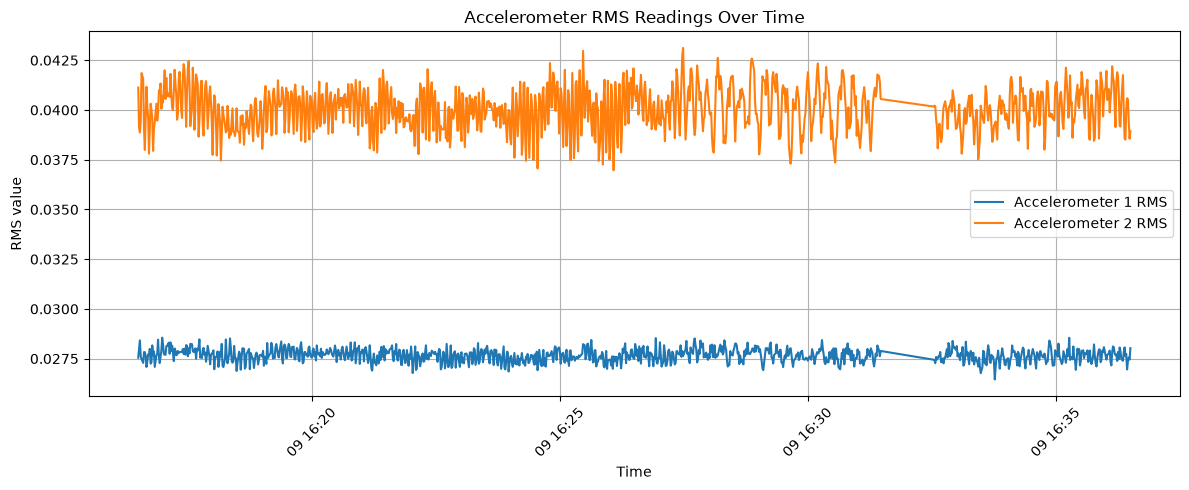

In [5]:

import matplotlib.pyplot as plt

# Plot accelerometer RMS values over time
plt.figure(figsize=(12, 5))

plt.plot(
    df["datetime"],
    df["Accelerometer1RMS"],
    label="Accelerometer 1 RMS"
)

plt.plot(
    df["datetime"],
    df["Accelerometer2RMS"],
    label="Accelerometer 2 RMS"
)

plt.xlabel("Time")
plt.ylabel("RMS value")
plt.title("Accelerometer RMS Readings Over Time")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [6]:

print("Anomaly label counts:")
print(df["anomaly"].value_counts())

print("\nChange-point label counts:")
print(df["changepoint"].value_counts())

print("\nRows with unusually high current:")
print(
    df.loc[
        df["Current"] > 10,
        ["datetime", "Current", "Voltage", "anomaly", "changepoint"]
    ]
)


Anomaly label counts:
anomaly
0.0    730
1.0    333
Name: count, dtype: int64

Change-point label counts:
changepoint
0.0    1059
1.0       4
Name: count, dtype: int64

Rows with unusually high current:
                datetime  Current   Voltage  anomaly  changepoint
1002 2020-03-09 16:35:27  232.734  0.580776      0.0          0.0


In [7]:
print("First 10 anomaly rows:")
print(df[df["anomaly"] == 1].head(10))

print("\nRows around the unusual current reading:")
print(
    df.loc[998:1005, [
        "datetime",
        "Current",
        "Voltage",
        "Accelerometer1RMS",
        "Accelerometer2RMS",
        "anomaly",
        "changepoint"
    ]]
)

First 10 anomaly rows:
               datetime  Accelerometer1RMS  Accelerometer2RMS   Current  \
560 2020-03-09 16:26:30           0.027489           0.040797  1.162620   
561 2020-03-09 16:26:31           0.028236           0.040921  0.478813   
562 2020-03-09 16:26:32           0.028028           0.040447  1.212860   
563 2020-03-09 16:26:33           0.027633           0.041229  0.953656   
564 2020-03-09 16:26:34           0.027954           0.040867  1.139300   
565 2020-03-09 16:26:35           0.027384           0.039770  0.449261   
566 2020-03-09 16:26:36           0.028119           0.040324  0.876434   
567 2020-03-09 16:26:38           0.027249           0.041766  0.784459   
568 2020-03-09 16:26:39           0.028023           0.040882  0.450071   
569 2020-03-09 16:26:40           0.027779           0.039835  0.857629   

     Pressure  Temperature  Thermocouple  Voltage  Volume Flow RateRMS  \
560 -0.273216      67.4538       24.2726  231.836              32.0000   
561

In [8]:
# Compare sensor readings for normal and anomaly-labelled rows
sensor_columns = [
    "Accelerometer1RMS",
    "Accelerometer2RMS",
    "Current",
    "Pressure",
    "Temperature",
    "Voltage",
    "Volume Flow RateRMS"
]

comparison = df.groupby("anomaly")[sensor_columns].mean().round(4)

print("Average sensor readings by anomaly label:")
print(comparison)

Average sensor readings by anomaly label:
         Accelerometer1RMS  Accelerometer2RMS  Current  Pressure  Temperature  \
anomaly                                                                         
0.0                 0.0276             0.0400   1.3048    0.0556      67.7797   
1.0                 0.0277             0.0401   0.9551    0.0330      68.1484   

          Voltage  Volume Flow RateRMS  
anomaly                                 
0.0      229.9408              32.1754  
1.0      229.8897              29.9309  


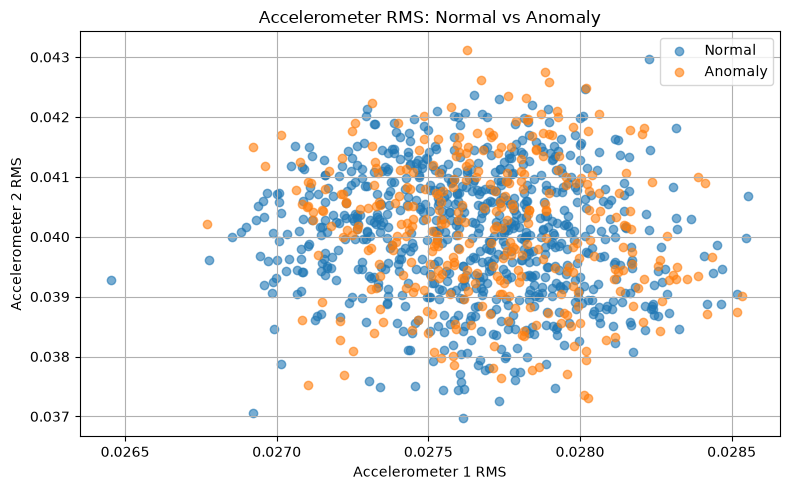

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for label, name in [(0, "Normal"), (1, "Anomaly")]:
    subset = df[df["anomaly"] == label]

    plt.scatter(
        subset["Accelerometer1RMS"],
        subset["Accelerometer2RMS"],
        label=name,
        alpha=0.6
    )

plt.xlabel("Accelerometer 1 RMS")
plt.ylabel("Accelerometer 2 RMS")
plt.title("Accelerometer RMS: Normal vs Anomaly")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
# Check time intervals between consecutive readings
time_diff = df["datetime"].diff().dt.total_seconds()

print("Time interval counts (seconds):")
print(time_diff.value_counts().sort_index())

print("\nAvailable columns:")
print(df.columns.tolist())

print("\nFirst 10 accelerometer readings:")
print(
    df[[
        "datetime",
        "Accelerometer1RMS",
        "Accelerometer2RMS"
    ]].head(10)
)

Time interval counts (seconds):
datetime
1.0     986
2.0      75
64.0      1
Name: count, dtype: int64

Available columns:
['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']

First 10 accelerometer readings:
             datetime  Accelerometer1RMS  Accelerometer2RMS
0 2020-03-09 16:16:30           0.027545           0.041127
1 2020-03-09 16:16:31           0.027997           0.039100
2 2020-03-09 16:16:32           0.028418           0.038872
3 2020-03-09 16:16:33           0.027625           0.039366
4 2020-03-09 16:16:34           0.027484           0.041854
5 2020-03-09 16:16:36           0.027288           0.041571
6 2020-03-09 16:16:37           0.027832           0.039037
7 2020-03-09 16:16:38           0.027826           0.037990
8 2020-03-09 16:16:39           0.027646           0.039669
9 2020-03-09 16:16:40           0.027084           0.041167


In [11]:
# Find time gaps greater than 2 seconds
time_diff = df["datetime"].diff().dt.total_seconds()

gap_rows = df.loc[
    time_diff > 2,
    ["datetime", "Accelerometer1RMS", "Accelerometer2RMS"]
].copy()

gap_rows["time_gap_seconds"] = time_diff[time_diff > 2]

print("Rows with time gaps greater than 2 seconds:")
print(gap_rows)

Rows with time gaps greater than 2 seconds:
               datetime  Accelerometer1RMS  Accelerometer2RMS  \
838 2020-03-09 16:32:32           0.027447           0.040173   

     time_gap_seconds  
838              64.0  


In [12]:
from pathlib import Path

# Create the output folder if needed
clean_folder = Path("../data/clean")
clean_folder.mkdir(parents=True, exist_ok=True)

# Save a separate copy of the current dataset
output_file = clean_folder / "sensor_data_clean.csv"
df.to_csv(output_file, index=False)

print("Dataset saved successfully!")
print("File location:", output_file.resolve())
print("Rows and columns:", df.shape)

Dataset saved successfully!
File location: C:\Users\Sowmya\OneDrive\Desktop\soumya\Sensor-Telemetry-Anomaly-detection-\data\clean\sensor_data_clean.csv
Rows and columns: (1063, 11)


In [ ]:
import pandas as pd
from pathlib import Path

clean_file = Path("../data/clean/sensor_data_clean.csv")

clean_df = pd.read_csv(clean_file)

print("Saved dataset loaded successfully!")
print("Shape:", clean_df.shape)
print("\nMissing values:")
print(clean_df.isnull().sum())
print("\nFirst 5 rows:")
print(clean_df.head())

Saved dataset loaded successfully!
Shape: (1063, 11)

Missing values:
datetime               0
Accelerometer1RMS      0
Accelerometer2RMS      0
Current                0
Pressure               0
Temperature            0
Thermocouple           0
Voltage                0
Volume Flow RateRMS    0
anomaly                0
changepoint            0
dtype: int64

First 5 rows:
              datetime  Accelerometer1RMS  Accelerometer2RMS   Current  \
0  2020-03-09 16:16:30           0.027545           0.041127  0.673506   
1  2020-03-09 16:16:31           0.027997           0.039100  0.772264   
2  2020-03-09 16:16:32           0.028418           0.038872  0.675520   
3  2020-03-09 16:16:33           0.027625           0.039366  0.566279   
4  2020-03-09 16:16:34           0.027484           0.041854  1.292170   

   Pressure  Temperature  Thermocouple  Voltage  Volume Flow RateRMS  anomaly  \
0  0.054711      67.8345       24.3164  240.513                 32.0      0.0   
1  0.054711      67.

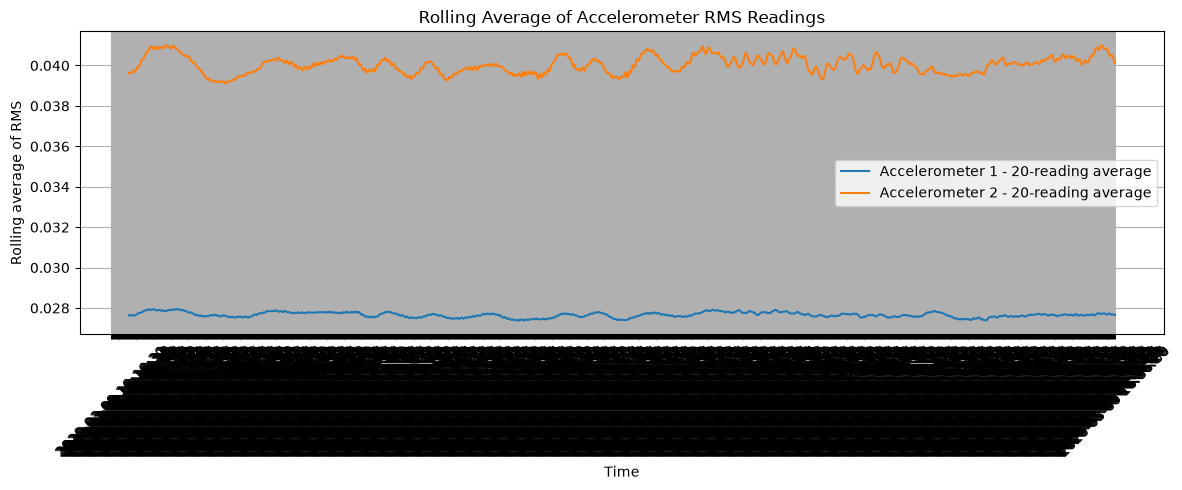

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    clean_df["datetime"],
    clean_df["Accelerometer1RMS"].rolling(window=20).mean(),
    label="Accelerometer 1 - 20-reading average"
)

plt.plot(
    clean_df["datetime"],
    clean_df["Accelerometer2RMS"].rolling(window=20).mean(),
    label="Accelerometer 2 - 20-reading average"
)

plt.xlabel("Time")
plt.ylabel("Rolling average of RMS")
plt.title("Rolling Average of Accelerometer RMS Readings")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    clean_df["datetime"],
    clean_df["Accelerometer1RMS"].rolling(20).mean(),
    label="Accelerometer 1"
)

ax.plot(
    clean_df["datetime"],
    clean_df["Accelerometer2RMS"].rolling(20).mean(),
    label="Accelerometer 2"
)

ax.set_xlabel("Time")
ax.set_ylabel("20-reading rolling average")
ax.set_title("Rolling Average of Accelerometer RMS Readings")

# Display only 6 time labels
positions = np.linspace(0, len(clean_df) - 1, 6, dtype=int)
ax.set_xticks(clean_df["datetime"].iloc[positions])
ax.tick_params(axis="x", rotation=30)

ax.legend()
ax.grid(True)
fig.tight_layout()
plt.show()

In [1]:

import pandas as pd

# Load the raw sensor dataset
df = pd.read_csv("../data/raw/1.csv", sep=";")

# Display dataset information
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)


Dataset shape: (1063, 11)

Column names:
['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']

First 5 rows:


,datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint
0,2020-03-09 16:16:30,0.027545,0.041127,0.673506,0.054711,67.8345,24.3164,240.513,32.0,0.0,0.0
1,2020-03-09 16:16:31,0.027997,0.039100,0.772264,0.054711,67.8704,24.3279,229.523,32.0,0.0,0.0
2,2020-03-09 16:16:32,0.028418,0.038872,0.675520,0.054711,67.7882,24.3261,242.708,32.0,0.0,0.0
3,2020-03-09 16:16:33,0.027625,0.039366,0.566279,-0.273216,67.7918,24.3323,229.709,32.0,0.0,0.0
4,2020-03-09 16:16:34,0.027484,0.041854,1.292170,0.054711,67.7368,24.3250,242.746,32.0,0.0,0.0



Data types:
datetime                   str
Accelerometer1RMS      float64
Accelerometer2RMS      float64
Current                float64
Pressure               float64
Temperature            float64
Thermocouple           float64
Voltage                float64
Volume Flow RateRMS    float64
anomaly                float64
changepoint            float64
dtype: object


In [2]:

# Summary of accelerometer readings
print("Accelerometer 1 summary:")
display(df["Accelerometer1RMS"].describe())

print("\nAccelerometer 2 summary:")
display(df["Accelerometer2RMS"].describe())

# Check how many anomaly records exist
print("\nAnomaly counts:")
display(df["anomaly"].value_counts())

Accelerometer 1 summary:


count    1063.000000
mean        0.027663
std         0.000333
min         0.026455
25%         0.027434
50%         0.027674
75%         0.027892
max         0.028554
Name: Accelerometer1RMS, dtype: float64


Accelerometer 2 summary:


count    1063.000000
mean        0.040037
std         0.001086
min         0.036972
25%         0.039276
50%         0.040098
75%         0.040828
max         0.043122
Name: Accelerometer2RMS, dtype: float64


Anomaly counts:


anomaly
0.0    730
1.0    333
Name: count, dtype: int64

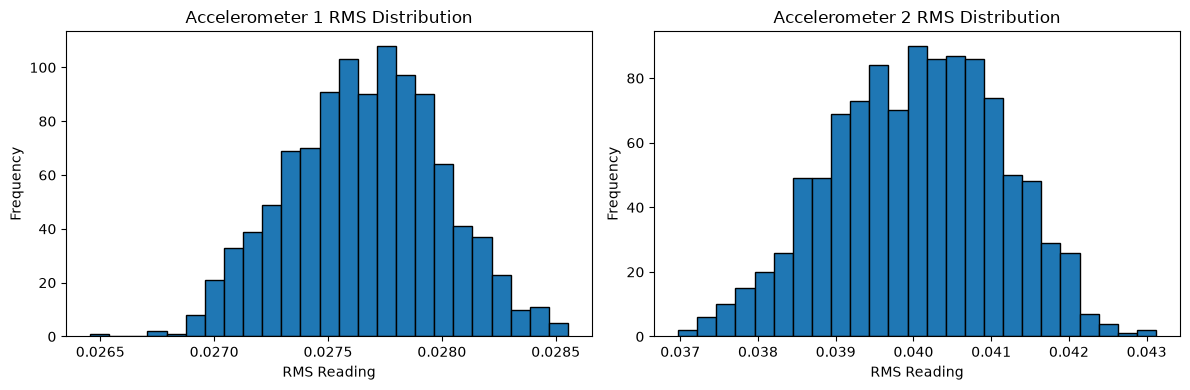

In [3]:

import matplotlib.pyplot as plt

# Create two histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["Accelerometer1RMS"], bins=25, edgecolor="black")
axes[0].set_title("Accelerometer 1 RMS Distribution")
axes[0].set_xlabel("RMS Reading")
axes[0].set_ylabel("Frequency")

axes[1].hist(df["Accelerometer2RMS"], bins=25, edgecolor="black")
axes[1].set_title("Accelerometer 2 RMS Distribution")
axes[1].set_xlabel("RMS Reading")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


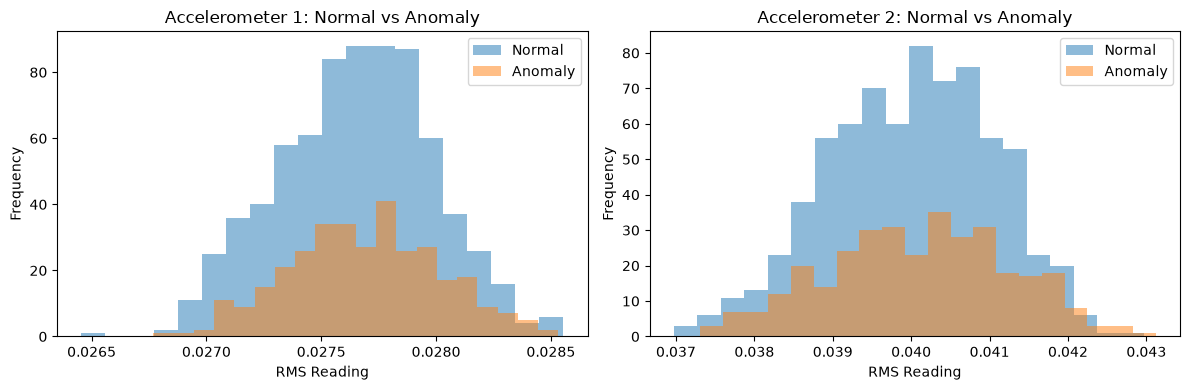

In [4]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for label, group in df.groupby("anomaly"):
    name = "Anomaly" if label == 1 else "Normal"

    axes[0].hist(
        group["Accelerometer1RMS"],
        bins=20,
        alpha=0.5,
        label=name
    )

    axes[1].hist(
        group["Accelerometer2RMS"],
        bins=20,
        alpha=0.5,
        label=name
    )

axes[0].set_title("Accelerometer 1: Normal vs Anomaly")
axes[0].set_xlabel("RMS Reading")
axes[0].set_ylabel("Frequency")
axes[0].legend()

axes[1].set_title("Accelerometer 2: Normal vs Anomaly")
axes[1].set_xlabel("RMS Reading")
axes[1].set_ylabel("Frequency")
axes[1].legend()

plt.tight_layout()
plt.show()


In [5]:

# Compare sensor readings by anomaly label
comparison = df.groupby("anomaly")[
    ["Accelerometer1RMS", "Accelerometer2RMS"]
].agg(["mean", "min", "max"])

print("RMS comparison: Normal vs Anomaly")
display(comparison)


RMS comparison: Normal vs Anomaly


Accelerometer1RMS                     Accelerometer2RMS            \
                     mean       min       max              mean       min   
anomaly                                                                     
0.0              0.027650  0.026455  0.028554          0.040007  0.036972   
1.0              0.027692  0.026769  0.028533          0.040102  0.037304   

                   
              max  
anomaly            
0.0      0.042974  
1.0      0.043122

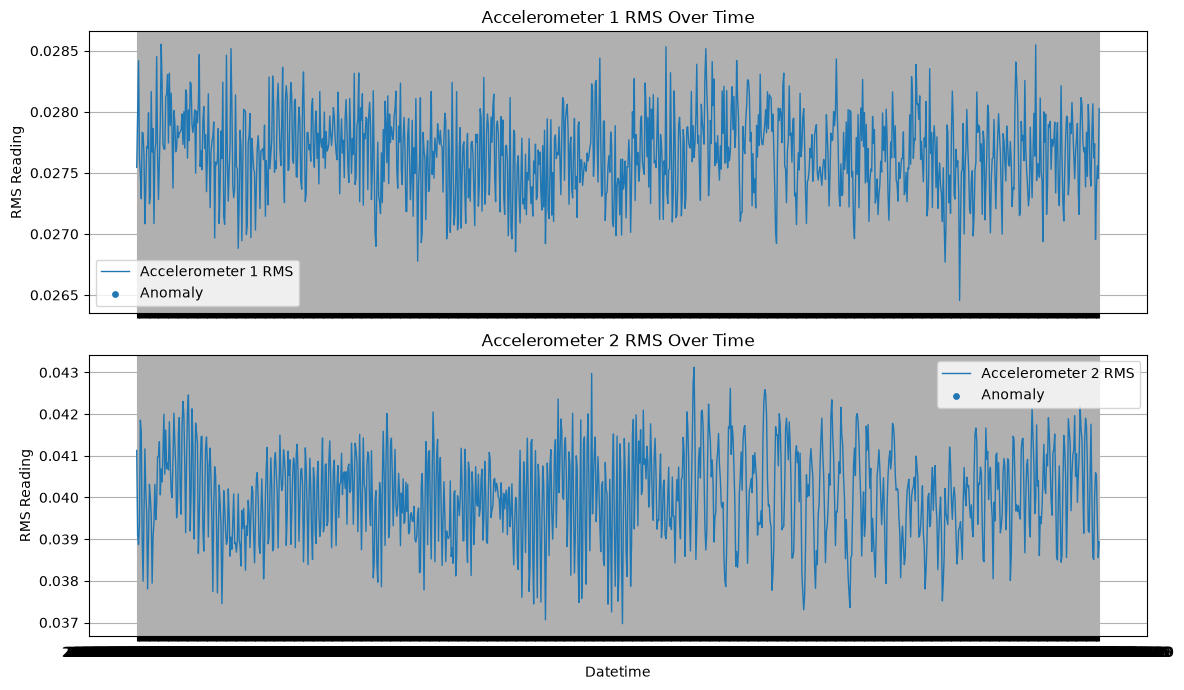

In [6]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Accelerometer 1
axes[0].plot(
    df["datetime"],
    df["Accelerometer1RMS"],
    label="Accelerometer 1 RMS",
    linewidth=1
)

anomalies = df["anomaly"] == 1

axes[0].scatter(
    df.loc[anomalies, "datetime"],
    df.loc[anomalies, "Accelerometer1RMS"],
    label="Anomaly",
    s=15
)

axes[0].set_title("Accelerometer 1 RMS Over Time")
axes[0].set_ylabel("RMS Reading")
axes[0].legend()
axes[0].grid(True)

# Accelerometer 2
axes[1].plot(
    df["datetime"],
    df["Accelerometer2RMS"],
    label="Accelerometer 2 RMS",
    linewidth=1
)

axes[1].scatter(
    df.loc[anomalies, "datetime"],
    df.loc[anomalies, "Accelerometer2RMS"],
    label="Anomaly",
    s=15
)

axes[1].set_title("Accelerometer 2 RMS Over Time")
axes[1].set_xlabel("Datetime")
axes[1].set_ylabel("RMS Reading")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


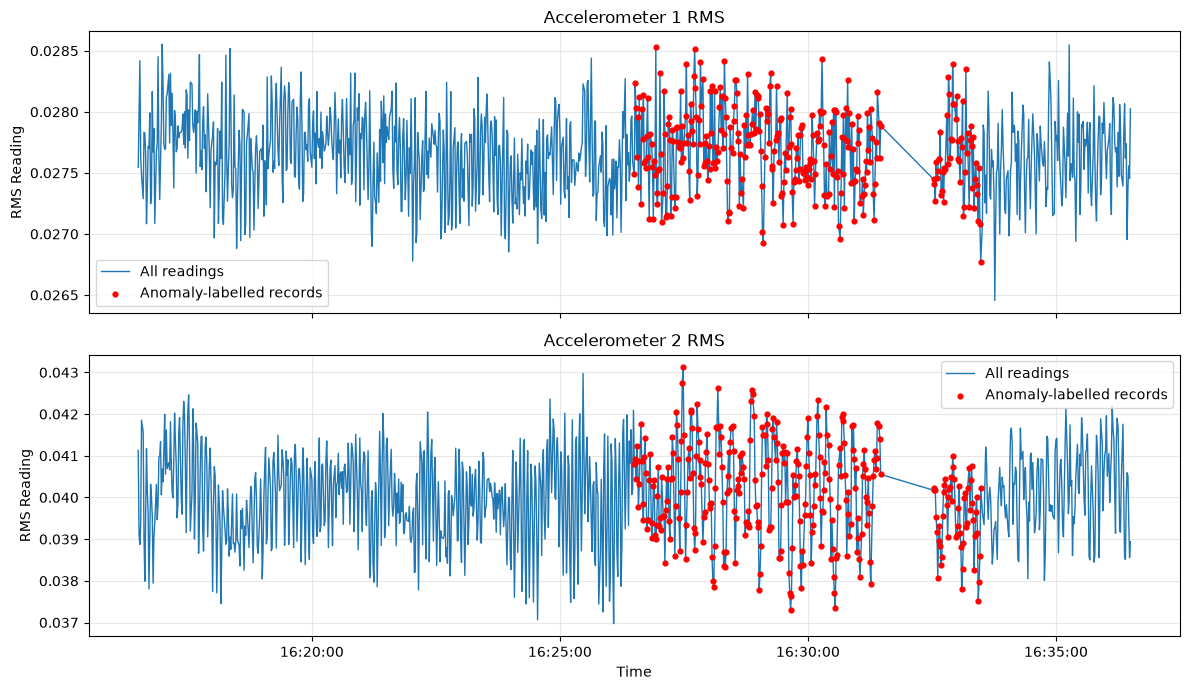

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Convert timestamps if not already converted
df["datetime"] = pd.to_datetime(df["datetime"])

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

sensor_columns = [
    ("Accelerometer1RMS", "Accelerometer 1 RMS"),
    ("Accelerometer2RMS", "Accelerometer 2 RMS")
]

anomalies = df["anomaly"] == 1

for ax, (column, title) in zip(axes, sensor_columns):
    ax.plot(
        df["datetime"], df[column],
        linewidth=1, label="All readings"
    )

    ax.scatter(
        df.loc[anomalies, "datetime"],
        df.loc[anomalies, column],
        color="red", s=12,
        label="Anomaly-labelled records",
        zorder=3
    )

    ax.set_title(title)
    ax.set_ylabel("RMS Reading")
    ax.legend()
    ax.grid(True, alpha=0.3)

# Display a manageable number of date labels
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=6))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
axes[-1].set_xlabel("Time")

plt.tight_layout()
plt.show()



In [2]:
import pandas as pd
from pathlib import Path

file_path = Path("data/raw/1.csv")

# Load the raw dataset
df = pd.read_csv(file_path, sep=";")

# Display dataset information
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

FileNotFoundError: [Errno 2] No such file or directory: 'data\\raw\\1.csv'

In [3]:
import pandas as pd
from pathlib import Path

file_path = Path("../data/raw/1.csv")

print("File exists:", file_path.exists())

if file_path.exists():
    df = pd.read_csv(file_path, sep=";")
    print("Dataset shape:", df.shape)
    display(df.head())

File exists: True
Dataset shape: (1063, 11)


,datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint
0,2020-03-09 16:16:30,0.027545,0.041127,0.673506,0.054711,67.8345,24.3164,240.513,32.0,0.0,0.0
1,2020-03-09 16:16:31,0.027997,0.039100,0.772264,0.054711,67.8704,24.3279,229.523,32.0,0.0,0.0
2,2020-03-09 16:16:32,0.028418,0.038872,0.675520,0.054711,67.7882,24.3261,242.708,32.0,0.0,0.0
3,2020-03-09 16:16:33,0.027625,0.039366,0.566279,-0.273216,67.7918,24.3323,229.709,32.0,0.0,0.0
4,2020-03-09 16:16:34,0.027484,0.041854,1.292170,0.054711,67.7368,24.3250,242.746,32.0,0.0,0.0


In [4]:
# Step 3: Check timestamp intervals

df["datetime"] = pd.to_datetime(df["datetime"])

# Calculate the time difference between consecutive rows
df["time_interval"] = df["datetime"].diff().dt.total_seconds()

print("Time interval counts:")
print(df["time_interval"].value_counts().sort_index())

print("\nMinimum time interval:",
      df["time_interval"].dropna().min(), "seconds")

print("Maximum time interval:",
      df["time_interval"].dropna().max(), "seconds")

print("\nFirst 10 time intervals:")
display(df[["datetime", "time_interval"]].head(10))

Time interval counts:
time_interval
1.0     986
2.0      75
64.0      1
Name: count, dtype: int64

Minimum time interval: 1.0 seconds
Maximum time interval: 64.0 seconds

First 10 time intervals:


,datetime,time_interval
0,2020-03-09 16:16:30,NaN
1,2020-03-09 16:16:31,1.0
2,2020-03-09 16:16:32,1.0
3,2020-03-09 16:16:33,1.0
4,2020-03-09 16:16:34,1.0
5,2020-03-09 16:16:36,2.0
6,2020-03-09 16:16:37,1.0
7,2020-03-09 16:16:38,1.0
8,2020-03-09 16:16:39,1.0
9,2020-03-09 16:16:40,1.0


In [5]:
# Step 4: Identify missing time intervals

gaps = df[df["time_interval"] > 1][
    ["datetime", "time_interval"]
]

print("Number of gaps:", len(gaps))
print("\nLocations of gaps:")
display(gaps)

print("\nSensor readings around the gaps:")

for index in gaps.index:
    print(f"\nGap at row {index}:")
    display(
        df.loc[
            max(0, index - 1):min(len(df) - 1, index + 1),
            ["datetime", "Accelerometer1RMS",
             "Accelerometer2RMS", "anomaly",
             "time_interval"]
        ]
    )

Number of gaps: 76

Locations of gaps:


,datetime,time_interval
5,2020-03-09 16:16:36,2.0
20,2020-03-09 16:16:52,2.0
34,2020-03-09 16:17:07,2.0
48,2020-03-09 16:17:22,2.0
60,2020-03-09 16:17:35,2.0
...,...,...
987,2020-03-09 16:35:11,2.0
1001,2020-03-09 16:35:26,2.0
1019,2020-03-09 16:35:45,2.0
1037,2020-03-09 16:36:04,2.0



Sensor readings around the gaps:

Gap at row 5:


,datetime,Accelerometer1RMS,Accelerometer2RMS,anomaly,time_interval
4,2020-03-09 16:16:34,0.027484,0.041854,0.0,1.0
5,2020-03-09 16:16:36,0.027288,0.041571,0.0,2.0
6,2020-03-09 16:16:37,0.027832,0.039037,0.0,1.0



Gap at row 20:


,datetime,Accelerometer1RMS,Accelerometer2RMS,anomaly,time_interval
19,2020-03-09 16:16:50,0.027085,0.039404,0.0,1.0
20,2020-03-09 16:16:52,0.027674,0.040315,0.0,2.0
21,2020-03-09 16:16:53,0.027747,0.039466,0.0,1.0


... (144 outputs left out)


Gap at row 1037:


,datetime,Accelerometer1RMS,Accelerometer2RMS,anomaly,time_interval
1036,2020-03-09 16:36:02,0.027677,0.040507,0.0,1.0
1037,2020-03-09 16:36:04,0.027777,0.041053,0.0,2.0
1038,2020-03-09 16:36:05,0.027905,0.039881,0.0,1.0



Gap at row 1053:


,datetime,Accelerometer1RMS,Accelerometer2RMS,anomaly,time_interval
1052,2020-03-09 16:36:19,0.027483,0.040408,0.0,1.0
1053,2020-03-09 16:36:21,0.027392,0.041756,0.0,2.0
1054,2020-03-09 16:36:22,0.027822,0.040001,0.0,1.0


In [7]:
# Step 5: Summarize time gaps

gap_summary = (
    df.loc[df["time_interval"] > 1, "time_interval"]
    .value_counts()
    .sort_index()
)

print("Time Gap Summary:")
print(gap_summary)

print("\nGaps greater than 2 seconds:")

large_gaps = df.loc[
    df["time_interval"] > 2,
    ["datetime", "time_interval"]
]

display(large_gaps)

print("\nTotal records:", len(df))
print("Total gaps greater than 1 second:",
      (df["time_interval"] > 1).sum())

Time Gap Summary:
time_interval
2.0     75
64.0     1
Name: count, dtype: int64

Gaps greater than 2 seconds:


,datetime,time_interval
838,2020-03-09 16:32:32,64.0



Total records: 1063
Total gaps greater than 1 second: 76


In [8]:
# Step 6: Inspect sensor columns

print("Dataset columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary of accelerometer readings:")
display(
    df[["Accelerometer1RMS", "Accelerometer2RMS"]]
    .describe()
)

Dataset columns:
['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint', 'time_interval']

Data types:
datetime               datetime64[us]
Accelerometer1RMS             float64
Accelerometer2RMS             float64
Current                       float64
Pressure                      float64
Temperature                   float64
Thermocouple                  float64
Voltage                       float64
Volume Flow RateRMS           float64
anomaly                       float64
changepoint                   float64
time_interval                 float64
dtype: object

Missing values:
datetime               0
Accelerometer1RMS      0
Accelerometer2RMS      0
Current                0
Pressure               0
Temperature            0
Thermocouple           0
Voltage                0
Volume Flow RateRMS    0
anomaly                0
changepoint            0
time_interval         

,Accelerometer1RMS,Accelerometer2RMS
count,1063.000000,1063.000000
mean,0.027663,0.040037
std,0.000333,0.001086
min,0.026455,0.036972
25%,0.027434,0.039276
50%,0.027674,0.040098
75%,0.027892,0.040828
max,0.028554,0.043122


In [9]:
# Step 7: Detailed data quality check

print("Missing values in each column:")
print(df.isnull().sum().to_string())

print("\nTotal missing values:",
      df.isnull().sum().sum())

print("\nAccelerometer RMS statistics:")
print(
    df[["Accelerometer1RMS", "Accelerometer2RMS"]]
    .describe()
    .to_string()
)

print("\nDuplicate rows:", df.duplicated().sum())

Missing values in each column:
datetime               0
Accelerometer1RMS      0
Accelerometer2RMS      0
Current                0
Pressure               0
Temperature            0
Thermocouple           0
Voltage                0
Volume Flow RateRMS    0
anomaly                0
changepoint            0
time_interval          1

Total missing values: 1

Accelerometer RMS statistics:
       Accelerometer1RMS  Accelerometer2RMS
count        1063.000000        1063.000000
mean            0.027663           0.040037
std             0.000333           0.001086
min             0.026455           0.036972
25%             0.027434           0.039276
50%             0.027674           0.040098
75%             0.027892           0.040828
max             0.028554           0.043122

Duplicate rows: 0


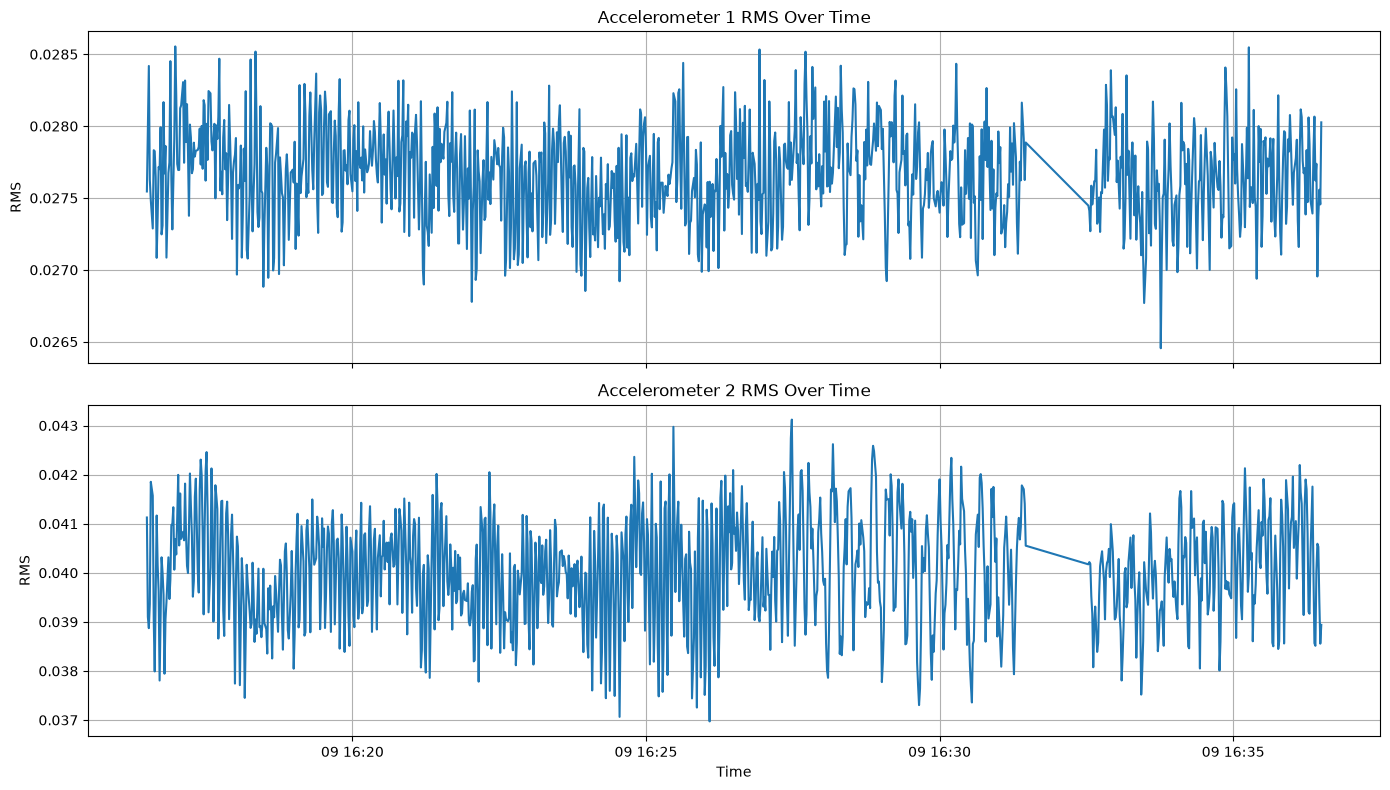

In [10]:
import matplotlib.pyplot as plt

# Step 8: Plot accelerometer RMS readings

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(
    df["datetime"],
    df["Accelerometer1RMS"]
)
axes[0].set_title("Accelerometer 1 RMS Over Time")
axes[0].set_ylabel("RMS")
axes[0].grid(True)

axes[1].plot(
    df["datetime"],
    df["Accelerometer2RMS"]
)
axes[1].set_title("Accelerometer 2 RMS Over Time")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("RMS")
axes[1].grid(True)

plt.tight_layout()
plt.show()

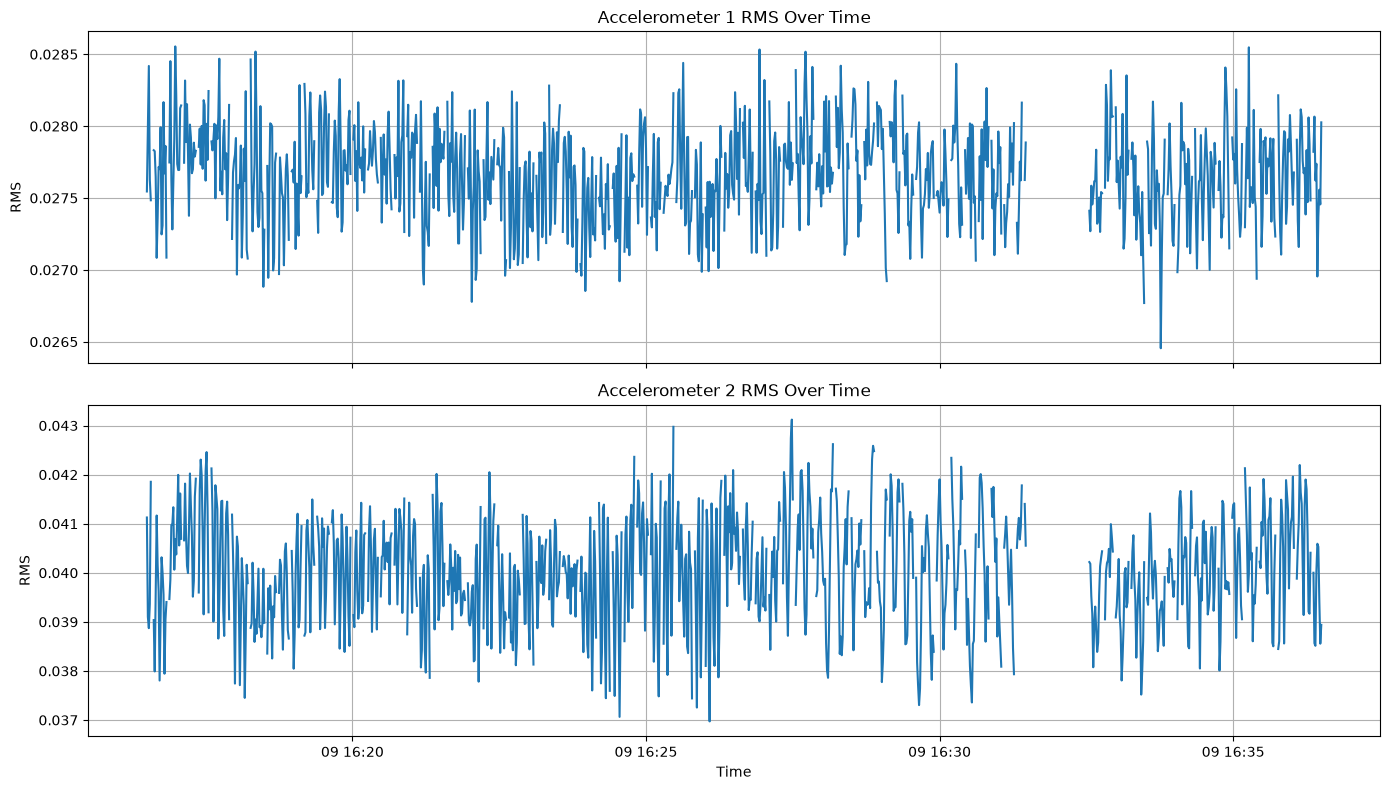

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

# Make sure timestamps are in datetime format
df["datetime"] = pd.to_datetime(df["datetime"])

# Calculate the time difference
time_diff = df["datetime"].diff().dt.total_seconds()

# Break the line at gaps greater than 1 second
acc1 = df["Accelerometer1RMS"].copy()
acc2 = df["Accelerometer2RMS"].copy()

acc1.loc[time_diff > 1] = float("nan")
acc2.loc[time_diff > 1] = float("nan")

# Plot corrected graphs
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(df["datetime"], acc1)
axes[0].set_title("Accelerometer 1 RMS Over Time")
axes[0].set_ylabel("RMS")
axes[0].grid(True)

axes[1].plot(df["datetime"], acc2)
axes[1].set_title("Accelerometer 2 RMS Over Time")
axes[1].set_ylabel("RMS")
axes[1].set_xlabel("Time")
axes[1].grid(True)

plt.tight_layout()
plt.show()

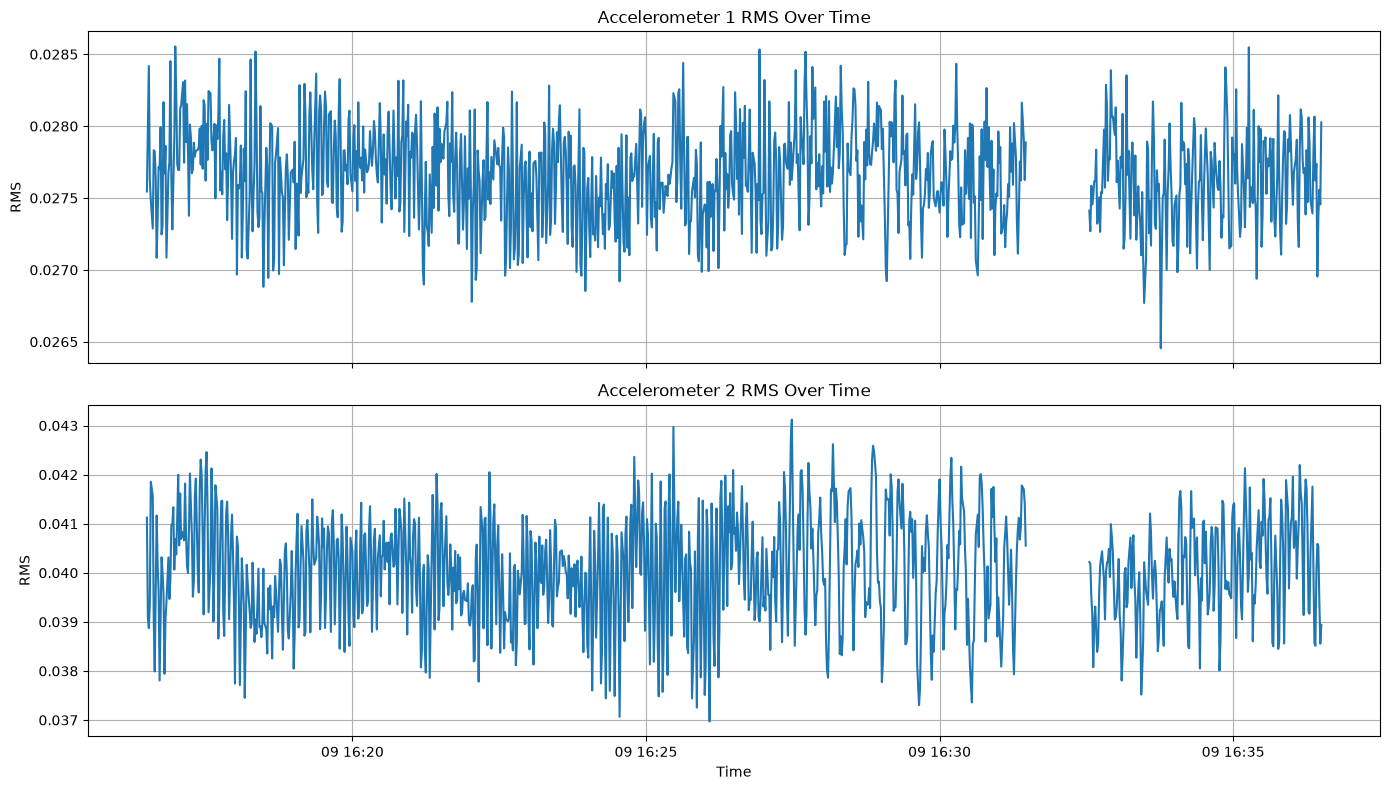

In [12]:
import matplotlib.pyplot as plt

# Calculate the time difference
time_diff = df["datetime"].diff().dt.total_seconds()

# Break lines only at gaps greater than 2 seconds
acc1 = df["Accelerometer1RMS"].copy()
acc2 = df["Accelerometer2RMS"].copy()

acc1.loc[time_diff > 2] = float("nan")
acc2.loc[time_diff > 2] = float("nan")

# Plot the sensor readings
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(df["datetime"], acc1)
axes[0].set_title("Accelerometer 1 RMS Over Time")
axes[0].set_ylabel("RMS")
axes[0].grid(True)

axes[1].plot(df["datetime"], acc2)
axes[1].set_title("Accelerometer 2 RMS Over Time")
axes[1].set_ylabel("RMS")
axes[1].set_xlabel("Time")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [1]:

from pathlib import Path
import pandas as pd

# Find the raw dataset
file_path = Path("data/raw/1.csv")

if not file_path.exists():
    file_path = Path("../data/raw/1.csv")

# Load the CSV using the semicolon separator
df = pd.read_csv(file_path, sep=";")

# Convert datetime column into datetime format
df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")

# Display basic information
print("Dataset loaded successfully!")
print("Dataset shape (rows, columns):", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


ImportError: DLL load failed while importing mtrand: An Application Control policy has blocked this file.

In [2]:

import csv
from pathlib import Path
from datetime import datetime
from collections import Counter

# Locate the dataset from either the project root or notebooks folder
candidates = [
    Path("data/raw/1.csv"),
    Path("../data/raw/1.csv")
]

file_path = next((p for p in candidates if p.exists()), None)

if file_path is None:
    raise FileNotFoundError("Could not find data/raw/1.csv")

# Read the semicolon-separated CSV
with file_path.open("r", encoding="utf-8-sig", newline="") as file:
    reader = csv.DictReader(file, delimiter=";")
    columns = reader.fieldnames
    rows = list(reader)

print("Dataset loaded successfully!")
print("File:", file_path.resolve())
print("Number of rows:", len(rows))
print("Number of columns:", len(columns))
print("\nColumns:", columns)

print("\nFirst 5 rows:")
for row in rows[:5]:
    print(row)

# Check missing values
print("\nMissing values per column:")
for column in columns:
    missing = sum(
        1 for row in rows
        if row.get(column) is None or not row[column].strip()
    )
    print(f"{column}: {missing}")

# Check duplicate records
print("\nDuplicate rows:", len(rows) - len({
    tuple(row.get(c, "") for c in columns) for row in rows
}))

# Inspect timestamp intervals
timestamps = []
for row in rows:
    try:
        timestamps.append(
            datetime.strptime(row["datetime"], "%Y-%m-%d %H:%M:%S")
        )
    except (ValueError, TypeError, KeyError):
        pass

timestamps.sort()
intervals = [
    int((timestamps[i] - timestamps[i - 1]).total_seconds())
    for i in range(1, len(timestamps))
]

print("\nValid timestamps:", len(timestamps))
print("Time interval counts (seconds):", dict(sorted(Counter(intervals).items())))
if intervals:
    print("Largest time gap (seconds):", max(intervals))


Dataset loaded successfully!
File: C:\Users\Sowmya\OneDrive\Desktop\soumya\Sensor-Telemetry-Anomaly-detection-\data\raw\1.csv
Number of rows: 1063
Number of columns: 11

Columns: ['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']

First 5 rows:
{'datetime': '2020-03-09 16:16:30', 'Accelerometer1RMS': '0.0275454', 'Accelerometer2RMS': '0.0411269', 'Current': '0.673506', 'Pressure': '0.054711', 'Temperature': '67.8345', 'Thermocouple': '24.3164', 'Voltage': '240.513', 'Volume Flow RateRMS': '32.0', 'anomaly': '0.0', 'changepoint': '0.0'}
{'datetime': '2020-03-09 16:16:31', 'Accelerometer1RMS': '0.027996899999999998', 'Accelerometer2RMS': '0.0391004', 'Current': '0.7722640000000001', 'Pressure': '0.054711', 'Temperature': '67.8704', 'Thermocouple': '24.3279', 'Voltage': '229.523', 'Volume Flow RateRMS': '32.0', 'anomaly': '0.0', 'changepoint': '0.0'}
{'datetime': '2020-03-

In [3]:

import csv
import statistics
from collections import Counter
from datetime import datetime
from pathlib import Path

file_path = Path("data/raw/1.csv")
if not file_path.exists():
    file_path = Path("../data/raw/1.csv")

with file_path.open("r", encoding="utf-8-sig", newline="") as f:
    rows = list(csv.DictReader(f, delimiter=";"))

# 1. Summary statistics for sensor measurements
sensor_columns = [
    "Accelerometer1RMS",
    "Accelerometer2RMS",
    "Current",
    "Pressure",
    "Temperature",
    "Thermocouple",
    "Voltage",
    "Volume Flow RateRMS"
]

print("SENSOR VALUE SUMMARY")
for column in sensor_columns:
    values = [float(row[column]) for row in rows if row[column].strip()]
    print(f"\n{column}")
    print("  Minimum:", round(min(values), 5))
    print("  Maximum:", round(max(values), 5))
    print("  Mean:", round(statistics.mean(values), 5))
    print("  Median:", round(statistics.median(values), 5))

# 2. Count anomaly and change-point labels
print("\nLABEL COUNTS")
for column in ["anomaly", "changepoint"]:
    counts = Counter(row[column].strip() for row in rows)
    print(column, dict(counts))

# 3. Find large timestamp gaps
timestamps = [
    datetime.strptime(row["datetime"], "%Y-%m-%d %H:%M:%S")
    for row in rows
]

print("\nTIME GAPS GREATER THAN 2 SECONDS")
for i in range(1, len(timestamps)):
    gap = (timestamps[i] - timestamps[i - 1]).total_seconds()
    if gap > 2:
        print(
            timestamps[i - 1], "to", timestamps[i],
            "| Gap:", int(gap), "seconds"
        )


SENSOR VALUE SUMMARY

Accelerometer1RMS
  Minimum: 0.02646
  Maximum: 0.02855
  Mean: 0.02766
  Median: 0.02767

Accelerometer2RMS
  Minimum: 0.03697
  Maximum: 0.04312
  Mean: 0.04004
  Median: 0.0401

Current
  Minimum: 0.39406
  Maximum: 232.734
  Mean: 1.19524
  Median: 1.00272

Pressure
  Minimum: -0.92907
  Maximum: 1.03849
  Mean: 0.04854
  Median: 0.05471

Temperature
  Minimum: 66.2019
  Maximum: 69.0982
  Mean: 67.89517
  Median: 67.955

Thermocouple
  Minimum: 24.217
  Maximum: 24.3323
  Mean: 24.2651
  Median: 24.2672

Voltage
  Minimum: 0.58078
  Maximum: 254.125
  Mean: 229.92482
  Median: 230.634

Volume Flow RateRMS
  Minimum: 28.04
  Maximum: 33.0
  Mean: 31.47227
  Median: 32.0

LABEL COUNTS
anomaly {'0.0': 730, '1.0': 333}
changepoint {'0.0': 1059, '1.0': 4}

TIME GAPS GREATER THAN 2 SECONDS
2020-03-09 16:31:28 to 2020-03-09 16:32:32 | Gap: 64 seconds


In [4]:

import csv
from pathlib import Path

file_path = Path("data/raw/1.csv")
if not file_path.exists():
    file_path = Path("../data/raw/1.csv")

with file_path.open("r", encoding="utf-8-sig", newline="") as f:
    rows = list(csv.DictReader(f, delimiter=";"))

for label in ["anomaly", "changepoint"]:
    flagged = [
        row for row in rows
        if float(row[label]) == 1.0
    ]

    print(f"\n{label.upper()}")
    print("Flagged records:", len(flagged))
    print("Label counts:")
    print({
        "0.0": sum(float(row[label]) == 0.0 for row in rows),
        "1.0": len(flagged)
    })

    for row in flagged:
        print(row["datetime"], "|", label, "=", row[label])



ANOMALY
Flagged records: 333
Label counts:
{'0.0': 730, '1.0': 333}
2020-03-09 16:26:30 | anomaly = 1.0
2020-03-09 16:26:31 | anomaly = 1.0
2020-03-09 16:26:32 | anomaly = 1.0
2020-03-09 16:26:33 | anomaly = 1.0
2020-03-09 16:26:34 | anomaly = 1.0
2020-03-09 16:26:35 | anomaly = 1.0
2020-03-09 16:26:36 | anomaly = 1.0
2020-03-09 16:26:38 | anomaly = 1.0
2020-03-09 16:26:39 | anomaly = 1.0
2020-03-09 16:26:40 | anomaly = 1.0
2020-03-09 16:26:41 | anomaly = 1.0
2020-03-09 16:26:42 | anomaly = 1.0
2020-03-09 16:26:43 | anomaly = 1.0
2020-03-09 16:26:44 | anomaly = 1.0
2020-03-09 16:26:45 | anomaly = 1.0
2020-03-09 16:26:46 | anomaly = 1.0
2020-03-09 16:26:47 | anomaly = 1.0
2020-03-09 16:26:48 | anomaly = 1.0
2020-03-09 16:26:49 | anomaly = 1.0
2020-03-09 16:26:51 | anomaly = 1.0
2020-03-09 16:26:52 | anomaly = 1.0
2020-03-09 16:26:53 | anomaly = 1.0
2020-03-09 16:26:54 | anomaly = 1.0
2020-03-09 16:26:55 | anomaly = 1.0
2020-03-09 16:26:56 | anomaly = 1.0
2020-03-09 16:26:57 | anomaly =

In [5]:

import csv
from pathlib import Path

file_path = Path("data/raw/1.csv")

if not file_path.exists():
    file_path = Path("../data/raw/1.csv")

with file_path.open("r", encoding="utf-8-sig", newline="") as f:
    rows = list(csv.DictReader(f, delimiter=";"))

# Find the record with the highest current reading
max_index = max(
    range(len(rows)),
    key=lambda i: float(rows[i]["Current"])
)

print("Highest current reading:")
print(rows[max_index])

# Display three records before and after it
print("\nNearby sensor readings:")

start = max(0, max_index - 3)
end = min(len(rows), max_index + 4)

for i in range(start, end):
    row = rows[i]
    print(
        row["datetime"],
        "| Current:", row["Current"],
        "| Accelerometer1RMS:", row["Accelerometer1RMS"],
        "| Accelerometer2RMS:", row["Accelerometer2RMS"],
        "| Anomaly:", row["anomaly"],
        "| Changepoint:", row["changepoint"]
    )

# Compare normal and anomalous current readings
print("\nCurrent comparison:")

for label in ["0.0", "1.0"]:
    values = [
        float(row["Current"])
        for row in rows
        if row["anomaly"] == label
    ]

    if values:
        print(
            "Anomaly =", label,
            "| Count =", len(values),
            "| Mean current =", round(sum(values) / len(values), 5),
            "| Maximum current =", round(max(values), 5)
        )


Highest current reading:
{'datetime': '2020-03-09 16:35:27', 'Accelerometer1RMS': '0.0277504', 'Accelerometer2RMS': '0.0402256', 'Current': '232.734', 'Pressure': '0.38263800000000003', 'Temperature': '67.3543', 'Thermocouple': '24.2247', 'Voltage': '0.5807760000000001', 'Volume Flow RateRMS': '31.0407', 'anomaly': '0.0', 'changepoint': '0.0'}

Nearby sensor readings:
2020-03-09 16:35:23 | Current: 0.595224 | Accelerometer1RMS: 0.027438900000000002 | Accelerometer2RMS: 0.039755900000000004 | Anomaly: 0.0 | Changepoint: 0.0
2020-03-09 16:35:24 | Current: 0.791495 | Accelerometer1RMS: 0.0269384 | Accelerometer2RMS: 0.040510199999999996 | Anomaly: 0.0 | Changepoint: 0.0
2020-03-09 16:35:26 | Current: 0.994151 | Accelerometer1RMS: 0.027999999999999997 | Accelerometer2RMS: 0.041276099999999996 | Anomaly: 0.0 | Changepoint: 0.0
2020-03-09 16:35:27 | Current: 232.734 | Accelerometer1RMS: 0.0277504 | Accelerometer2RMS: 0.0402256 | Anomaly: 0.0 | Changepoint: 0.0
2020-03-09 16:35:28 | Current: 

In [6]:
import pandas as pd

# Load the sensor dataset
df = pd.read_csv("data/raw/sensor_data.csv")

# Convert Current column to numeric
df["Current"] = pd.to_numeric(df["Current"], errors="coerce")

# Display the 10 highest current readings
highest_current = df.nlargest(10, "Current")

print(highest_current[
    ["datetime", "Current", "anomaly", "changepoint"]
])

ImportError: DLL load failed while importing mtrand: An Application Control policy has blocked this file.

In [7]:

# Task 3: Detect unusual current readings

import math

def is_number(value):
    try:
        return math.isfinite(float(value))
    except (ValueError, TypeError):
        return False

# Get valid current readings
current_values = [
    float(row["Current"])
    for row in rows
    if is_number(row.get("Current", ""))
]

if not current_values:
    print("No valid current readings found.")
else:
    # Calculate quartiles
    current_values.sort()
    n = len(current_values)

    q1 = current_values[int(n * 0.25)]
    q3 = current_values[int(n * 0.75)]

    # Calculate IQR limits
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    print("Q1:", round(q1, 5))
    print("Q3:", round(q3, 5))
    print("IQR:", round(iqr, 5))
    print("Lower limit:", round(lower_limit, 5))
    print("Upper limit:", round(upper_limit, 5))

    # Identify possible outliers
    outliers = [
        row for row in rows
        if is_number(row.get("Current", ""))
        and (
            float(row["Current"]) < lower_limit
            or float(row["Current"]) > upper_limit
        )
    ]

    print("\nTotal possible outliers:", len(outliers))

    for row in outliers[:10]:
        print(
            row["datetime"],
            "| Current:", row["Current"],
            "| Anomaly:", row["anomaly"]
        )


Q1: 0.75323
Q3: 1.19497
IQR: 0.44174
Lower limit: 0.09062
Upper limit: 1.85758

Total possible outliers: 1
2020-03-09 16:35:27 | Current: 232.734 | Anomaly: 0.0


In [8]:

# Task 4: Compare current and accelerometer readings

print("Sensor readings around the current spike:\n")

for i in range(max(0, max_index - 5),
               min(len(rows), max_index + 6)):

    row = rows[i]

    print(
        row["datetime"],
        "| Current:", row["Current"],
        "| Acc1 RMS:", row["Accelerometer1RMS"],
        "| Acc2 RMS:", row["Accelerometer2RMS"]
    )


Sensor readings around the current spike:

2020-03-09 16:35:21 | Current: 1.1728399999999999 | Acc1 RMS: 0.0281127 | Acc2 RMS: 0.0395406
2020-03-09 16:35:22 | Current: 0.415865 | Acc1 RMS: 0.027504 | Acc2 RMS: 0.039370999999999996
2020-03-09 16:35:23 | Current: 0.595224 | Acc1 RMS: 0.027438900000000002 | Acc2 RMS: 0.039755900000000004
2020-03-09 16:35:24 | Current: 0.791495 | Acc1 RMS: 0.0269384 | Acc2 RMS: 0.040510199999999996
2020-03-09 16:35:26 | Current: 0.994151 | Acc1 RMS: 0.027999999999999997 | Acc2 RMS: 0.041276099999999996
2020-03-09 16:35:27 | Current: 232.734 | Acc1 RMS: 0.0277504 | Acc2 RMS: 0.0402256
2020-03-09 16:35:28 | Current: 0.731046 | Acc1 RMS: 0.0279807 | Acc2 RMS: 0.040096
2020-03-09 16:35:29 | Current: 0.45950699999999994 | Acc1 RMS: 0.027160300000000002 | Acc2 RMS: 0.0410352
2020-03-09 16:35:30 | Current: 0.497475 | Acc1 RMS: 0.027374799999999998 | Acc2 RMS: 0.0407582
2020-03-09 16:35:31 | Current: 0.835224 | Acc1 RMS: 0.027896299999999995 | Acc2 RMS: 0.0419108


In [9]:

# Task 5: Detect vibration outliers using the IQR method

def find_outliers(column):
    values = sorted(
        float(row[column])
        for row in rows
        if is_number(row.get(column, ""))
    )

    n = len(values)
    if n < 4:
        print(column, ": Not enough valid readings")
        return

    q1 = values[int(n * 0.25)]
    q3 = values[int(n * 0.75)]
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = [
        row for row in rows
        if is_number(row.get(column, ""))
        and (
            float(row[column]) < lower
            or float(row[column]) > upper
        )
    ]

    print("\nSensor:", column)
    print("Lower limit:", round(lower, 6))
    print("Upper limit:", round(upper, 6))
    print("Number of outliers:", len(outliers))

    for row in outliers[:5]:
        print(
            row["datetime"],
            "| Value:", row[column],
            "| Anomaly:", row["anomaly"]
        )


find_outliers("Accelerometer1RMS")
find_outliers("Accelerometer2RMS")



Sensor: Accelerometer1RMS
Lower limit: 0.026745
Upper limit: 0.028581
Number of outliers: 1
2020-03-09 16:33:46 | Value: 0.026455000000000003 | Anomaly: 0.0

Sensor: Accelerometer2RMS
Lower limit: 0.036938
Upper limit: 0.043164
Number of outliers: 0


In [10]:
# Task 6: Compare vibration readings by anomaly label

for column in ["Accelerometer1RMS", "Accelerometer2RMS"]:
    print("\nSensor:", column)

    for label in ["0.0", "1.0"]:
        values = [
            float(row[column])
            for row in rows
            if row.get("anomaly") == label
            and is_number(row.get(column, ""))
        ]

        if values:
            print(
                "Anomaly =", label,
                "| Count =", len(values),
                "| Mean =", round(sum(values) / len(values), 6),
                "| Maximum =", round(max(values), 6)
            )


Sensor: Accelerometer1RMS
Anomaly = 0.0 | Count = 730 | Mean = 0.02765 | Maximum = 0.028554
Anomaly = 1.0 | Count = 333 | Mean = 0.027692 | Maximum = 0.028533

Sensor: Accelerometer2RMS
Anomaly = 0.0 | Count = 730 | Mean = 0.040007 | Maximum = 0.042974
Anomaly = 1.0 | Count = 333 | Mean = 0.040102 | Maximum = 0.043122


In [11]:
# Task 7: Calculate vibration difference between normal and anomalous readings

for column in ["Accelerometer1RMS", "Accelerometer2RMS"]:
    print("\nSensor:", column)

    normal_values = [
        float(row[column])
        for row in rows
        if row.get("anomaly") == "0.0"
        and is_number(row.get(column, ""))
    ]

    anomaly_values = [
        float(row[column])
        for row in rows
        if row.get("anomaly") == "1.0"
        and is_number(row.get(column, ""))
    ]

    if normal_values and anomaly_values:
        normal_mean = sum(normal_values) / len(normal_values)
        anomaly_mean = sum(anomaly_values) / len(anomaly_values)

        print("Normal Mean:", round(normal_mean, 6))
        print("Anomaly Mean:", round(anomaly_mean, 6))
        print(
            "Mean Difference:",
            round(anomaly_mean - normal_mean, 6)
        )

        if anomaly_mean > normal_mean:
            print("Result: Vibration is higher during anomalies.")
        elif anomaly_mean < normal_mean:
            print("Result: Vibration is lower during anomalies.")
        else:
            print("Result: Both mean vibration values are equal.")


Sensor: Accelerometer1RMS
Normal Mean: 0.02765
Anomaly Mean: 0.027692
Mean Difference: 4.2e-05
Result: Vibration is higher during anomalies.

Sensor: Accelerometer2RMS
Normal Mean: 0.040007
Anomaly Mean: 0.040102
Mean Difference: 9.5e-05
Result: Vibration is higher during anomalies.


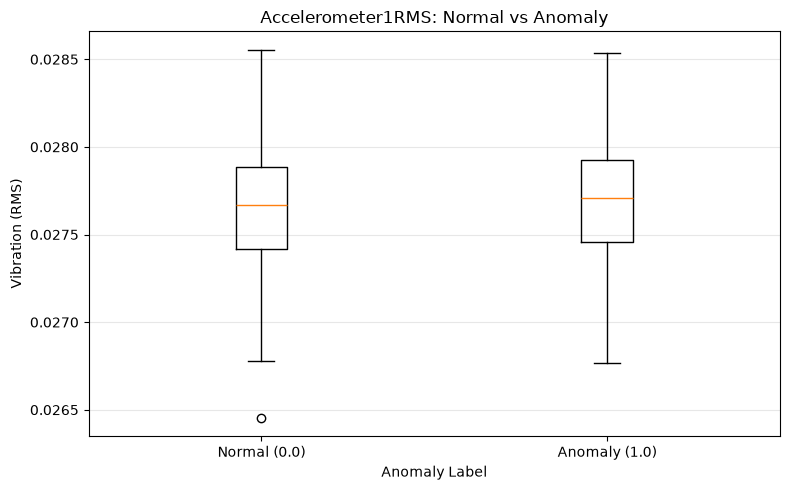

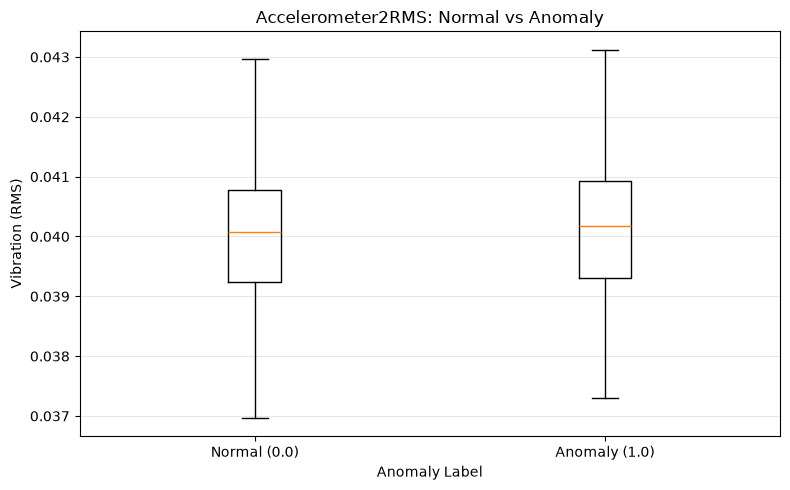

In [12]:
# Task 8: Visualize vibration readings by anomaly label

import matplotlib.pyplot as plt

for column in ["Accelerometer1RMS", "Accelerometer2RMS"]:
    normal_values = [
        float(row[column])
        for row in rows
        if row.get("anomaly") == "0.0"
        and is_number(row.get(column, ""))
    ]

    anomaly_values = [
        float(row[column])
        for row in rows
        if row.get("anomaly") == "1.0"
        and is_number(row.get(column, ""))
    ]

    plt.figure(figsize=(8, 5))

    plt.boxplot(
        [normal_values, anomaly_values],
        tick_labels=["Normal (0.0)", "Anomaly (1.0)"]
    )

    plt.title(f"{column}: Normal vs Anomaly")
    plt.xlabel("Anomaly Label")
    plt.ylabel("Vibration (RMS)")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [1]:

from pathlib import Path

project_root = Path.cwd()

# Move to the project folder if currently inside notebooks
if project_root.name == "notebooks":
    project_root = project_root.parent

print("Project folder:", project_root)
print("\nCSV files found:")

for file in project_root.rglob("*.csv"):
    print(file.relative_to(project_root))


Project folder: c:\Users\Sowmya\OneDrive\Desktop\soumya\Sensor-Telemetry-Anomaly-detection-

CSV files found:
data\clean\sensor_data_clean.csv
data\raw\1.csv
.venv-clean\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-arccos.csv
.venv-clean\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-arccosh.csv
.venv-clean\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-arcsin.csv
.venv-clean\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-arcsinh.csv
.venv-clean\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-arctan.csv
.venv-clean\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-arctanh.csv
.venv-clean\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-cbrt.csv
.venv-clean\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-cos.csv
.venv-clean\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-cosh.csv
.venv-clean\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-exp.csv

In [2]:

from pathlib import Path
import pandas as pd

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

raw_file = project_root / "data" / "raw" / "1.csv"
clean_file = project_root / "data" / "clean" / "sensor_data_clean.csv"

for file in [raw_file, clean_file]:
    print("\n" + "=" * 50)
    print("File:", file.name)

    data = pd.read_csv(file, sep=";")

    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    print("\nFirst 3 rows:")
    display(data.head(3))



File: 1.csv
Shape: (1063, 11)
Columns: ['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']

First 3 rows:


,datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint
0,2020-03-09 16:16:30,0.027545,0.041127,0.673506,0.054711,67.8345,24.3164,240.513,32.0,0.0,0.0
1,2020-03-09 16:16:31,0.027997,0.039100,0.772264,0.054711,67.8704,24.3279,229.523,32.0,0.0,0.0
2,2020-03-09 16:16:32,0.028418,0.038872,0.675520,0.054711,67.7882,24.3261,242.708,32.0,0.0,0.0



File: sensor_data_clean.csv
Shape: (1063, 1)
Columns: ['datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint']

First 3 rows:


,"datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint"
0,"2020-03-09 16:16:30,0.0275454,0.0411269,0.6735..."
1,"2020-03-09 16:16:31,0.0279968999999999,0.03910..."
2,"2020-03-09 16:16:32,0.0284184,0.038872,0.67552..."


In [3]:

from pathlib import Path
import pandas as pd

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

clean_file = project_root / "data" / "clean" / "sensor_data_clean.csv"

# This file is comma-separated
clean_df = pd.read_csv(clean_file, sep=",")

print("Dataset shape:", clean_df.shape)
print("\nColumn names:")
print(clean_df.columns.tolist())

print("\nFirst 3 rows:")
display(clean_df.head(3))


Dataset shape: (1063, 11)

Column names:
['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']

First 3 rows:


,datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint
0,2020-03-09 16:16:30,0.027545,0.041127,0.673506,0.054711,67.8345,24.3164,240.513,32.0,0.0,0.0
1,2020-03-09 16:16:31,0.027997,0.039100,0.772264,0.054711,67.8704,24.3279,229.523,32.0,0.0,0.0
2,2020-03-09 16:16:32,0.028418,0.038872,0.675520,0.054711,67.7882,24.3261,242.708,32.0,0.0,0.0


In [7]:

import pandas as pd
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

file_path = project_root / "data" / "raw" / "1.csv"

df = pd.read_csv(file_path, sep=";")
df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")

# Calculate time between consecutive records
df["time_interval_seconds"] = (
    df["datetime"].diff().dt.total_seconds()
)

print("Time interval counts:")
print(df["time_interval_seconds"].value_counts().sort_index())

print("\nIntervals longer than 1 second:")
print(
    df.loc[
        df["time_interval_seconds"] > 1,
        ["datetime", "time_interval_seconds"]
    ]
)

print("\nMissing timestamps:", df["datetime"].isna().sum())


Time interval counts:
time_interval_seconds
1.0     986
2.0      75
64.0      1
Name: count, dtype: int64

Intervals longer than 1 second:
                datetime  time_interval_seconds
5    2020-03-09 16:16:36                    2.0
20   2020-03-09 16:16:52                    2.0
34   2020-03-09 16:17:07                    2.0
48   2020-03-09 16:17:22                    2.0
60   2020-03-09 16:17:35                    2.0
...                  ...                    ...
987  2020-03-09 16:35:11                    2.0
1001 2020-03-09 16:35:26                    2.0
1019 2020-03-09 16:35:45                    2.0
1037 2020-03-09 16:36:04                    2.0
1053 2020-03-09 16:36:21                    2.0

[76 rows x 2 columns]

Missing timestamps: 0



### Task 10: Sensor Timestamp Interval Analysis

**Objective:** Examine the time intervals between consecutive sensor records.

**Results:**
- Total sensor records: 1,063
- Missing timestamps: 0
- Records separated by 1 second: 986
- Records separated by 2 seconds: 75
- Records separated by 64 seconds: 1

**Observations:**
1. Most records are separated by one second.
2. Some records are separated by two seconds.
3. One 64-second gap may indicate an interruption in data recording.
4. The timestamps are present, but the intervals are not completely uniform.

**Conclusion:** The dataset has mostly regular timestamps, with some longer intervals that should be considered during time-series analysis.

**Limitation:** Timestamp intervals do not establish the sensor's internal waveform sampling rate. Raw waveform samples and a documented sampling rate are required for reliable FFT-based frequency-band analysis.


In [11]:

from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

print("Documentation files:")

for pattern in ["README*", "*.md", "*.txt"]:
    for file in project_root.glob(pattern):
        if ".venv" not in str(file):
            print(file.name)


Documentation files:


In [12]:

from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

print("Project files and folders:")

for item in project_root.iterdir():
    if item.name not in {".venv", ".venv-clean", ".git"}:
        print(item.name, "(folder)" if item.is_dir() else "(file)")

print("\nDocumentation files in project folders:")

for item in project_root.rglob("*"):
    if (
        item.is_file()
        and item.suffix.lower() in {".md", ".txt", ".rst"}
        and ".venv" not in str(item)
        and ".git" not in str(item)
    ):
        print(item.relative_to(project_root))


Project files and folders:
data (folder)
docker-compose.yml (file)
notebooks (folder)
src (folder)

Documentation files in project folders:


In [13]:

from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

for folder_name in ["src", "data"]:
    folder = project_root / folder_name

    print(f"\n--- {folder_name.upper()} ---")

    for item in folder.rglob("*"):
        if item.is_file():
            print(item.relative_to(project_root))



--- SRC ---
src\preprocessing.py
src\volatility_analysis.py

--- DATA ---
data\clean\sensor_data_clean.csv
data\raw\1.csv


In [14]:

from pathlib import Path

# Find the project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Inspect both source files
for filename in ["preprocessing.py", "volatility_analysis.py"]:
    file_path = project_root / "src" / filename

    print("\n" + "=" * 50)
    print("FILE:", filename)
    print("=" * 50)

    if file_path.exists():
        print(file_path.read_text(encoding="utf-8"))
    else:
        print("File not found:", file_path)



FILE: preprocessing.py


FILE: volatility_analysis.py

from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

for filename in ["preprocessing.py", "volatility_analysis.py"]:
    file_path = project_root / "src" / filename

    print(f"\n{'=' * 50}")
    print(f"FILE: {filename}")
    print("=" * 50)

    if file_path.exists():
        print(file_path.read_text(encoding="utf-8"))
    else:
        print("File not found.")




In [15]:

from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

for filename in ["preprocessing.py", "volatility_analysis.py"]:
    file_path = project_root / "src" / filename

    print(f"\n--- {filename} ---")

    if file_path.exists():
        content = file_path.read_text(encoding="utf-8")
        print("File size:", len(content), "characters")

        if content.strip():
            print(content[:5000])
        else:
            print("This file is empty.")
    else:
        print("File not found.")



--- preprocessing.py ---
File size: 0 characters
This file is empty.

--- volatility_analysis.py ---
File size: 447 characters

from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

for filename in ["preprocessing.py", "volatility_analysis.py"]:
    file_path = project_root / "src" / filename

    print(f"\n{'=' * 50}")
    print(f"FILE: {filename}")
    print("=" * 50)

    if file_path.exists():
        print(file_path.read_text(encoding="utf-8"))
    else:
        print("File not found.")




In [16]:

from pathlib import Path
import pandas as pd

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

df = pd.read_csv(
    project_root / "data" / "raw" / "1.csv",
    sep=";"
)

print("Dataset shape:", df.shape)

print("\nAvailable columns:")
for column in df.columns:
    print("-", column)

print("\nPotential waveform-related columns:")
keywords = ["wave", "signal", "frequency", "sample", "vibration", "accelerometer"]

matches = [
    column for column in df.columns
    if any(word in column.lower() for word in keywords)
]

print(matches if matches else "No explicit raw waveform or sampling-rate columns found.")


Dataset shape: (1063, 11)

Available columns:
- datetime
- Accelerometer1RMS
- Accelerometer2RMS
- Current
- Pressure
- Temperature
- Thermocouple
- Voltage
- Volume Flow RateRMS
- anomaly
- changepoint

Potential waveform-related columns:
['Accelerometer1RMS', 'Accelerometer2RMS']



### Task 15: Frequency-Band Analysis Feasibility Assessment

**Objective:** Determine whether the available sensor dataset supports FFT-based frequency-band analysis.

**Dataset findings:**
- Total records: 1,063
- Total columns: 11
- Available vibration-related measurements: Accelerometer1RMS and Accelerometer2RMS
- Anomaly and changepoint labels are available.
- No explicit raw waveform samples or sampling-rate metadata were identified in the dataset columns.

**Observation:**
The accelerometer columns contain RMS summary measurements. These describe vibration magnitude but do not provide the individual high-frequency waveform samples needed to calculate a reliable FFT spectrum.

**Conclusion:**
The current dataset supports time-series analysis, anomaly comparison, and vibration magnitude visualization. However, FFT-based frequency-band analysis cannot be reliably performed using these RMS summaries alone.

**Next requirement:**
Obtain raw vibration waveform data and its documented sampling rate from the dataset provider or project team before performing FFT analysis.


Sampling rate: 1000 Hz
Duration: 2 seconds
Number of samples: 2000


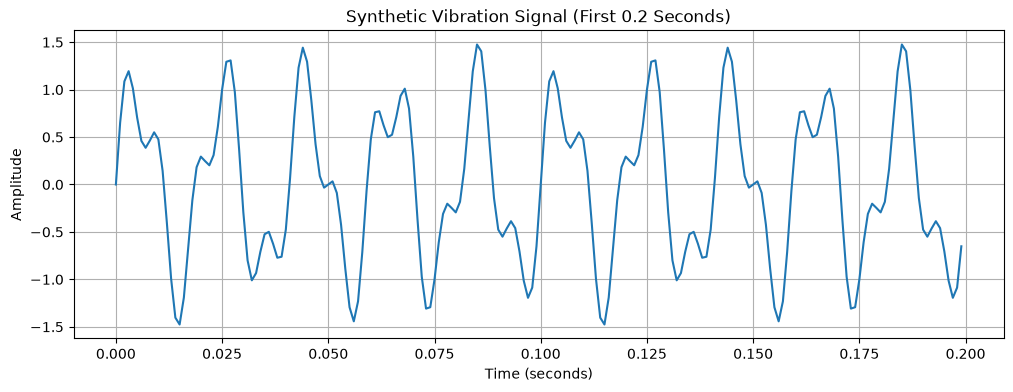

In [17]:

import numpy as np
import matplotlib.pyplot as plt

# Create a sample signal
sampling_rate = 1000  # samples per second (Hz)
duration = 2          # seconds

time = np.arange(0, duration, 1 / sampling_rate)

# Synthetic vibration containing 50 Hz and 120 Hz
signal = (
    1.0 * np.sin(2 * np.pi * 50 * time)
    + 0.5 * np.sin(2 * np.pi * 120 * time)
)

print("Sampling rate:", sampling_rate, "Hz")
print("Duration:", duration, "seconds")
print("Number of samples:", len(signal))

plt.figure(figsize=(12, 4))
plt.plot(time[:200], signal[:200])
plt.title("Synthetic Vibration Signal (First 0.2 Seconds)")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


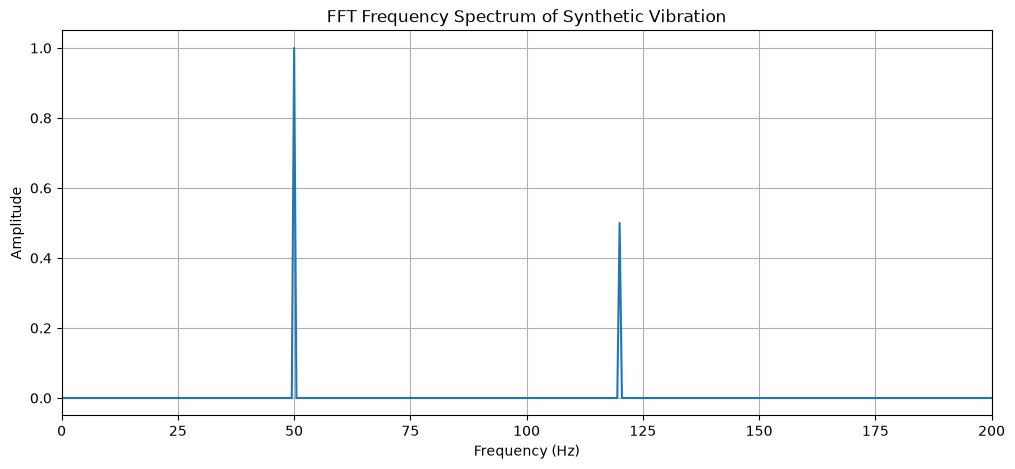

Top frequency peaks:
Frequency: 50.0 Hz, Amplitude: 1.00
Frequency: 120.0 Hz, Amplitude: 0.50
Frequency: 120.5 Hz, Amplitude: 0.00
Frequency: 119.5 Hz, Amplitude: 0.00
Frequency: 384.0 Hz, Amplitude: 0.00


In [18]:

# Task 17: FFT Frequency Spectrum Analysis

# Calculate the FFT
fft_values = np.fft.rfft(signal)

# Calculate the corresponding frequencies
frequencies = np.fft.rfftfreq(len(signal), d=1/sampling_rate)

# Calculate the amplitude spectrum
amplitude = np.abs(fft_values) / len(signal)

# Adjust amplitudes for a one-sided spectrum
amplitude[1:-1] = 2 * amplitude[1:-1]

# Plot the frequency spectrum
plt.figure(figsize=(12, 5))
plt.plot(frequencies, amplitude)

plt.title("FFT Frequency Spectrum of Synthetic Vibration")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.xlim(0, 200)
plt.grid(True)
plt.show()

# Find the strongest frequency peaks
peak_indices = np.argsort(amplitude)[-5:][::-1]

print("Top frequency peaks:")
for index in peak_indices:
    print(f"Frequency: {frequencies[index]:.1f} Hz, "
          f"Amplitude: {amplitude[index]:.2f}")


In [19]:

# Task 18: Group frequencies into bands

frequency_bands = {
    "Low (0-50 Hz)": (0, 50),
    "Medium (50-100 Hz)": (50, 100),
    "High (100-200 Hz)": (100, 200)
}

print("Frequency Band Analysis (Synthetic Signal)")
print("-" * 45)

for band_name, (lower, upper) in frequency_bands.items():
    band_mask = (frequencies >= lower) & (frequencies < upper)

    band_amplitude = amplitude[band_mask]
    total_amplitude = band_amplitude.sum()

    print(f"{band_name}: {total_amplitude:.2f}")


Frequency Band Analysis (Synthetic Signal)
---------------------------------------------
Low (0-50 Hz): 0.00
Medium (50-100 Hz): 1.00
High (100-200 Hz): 0.50


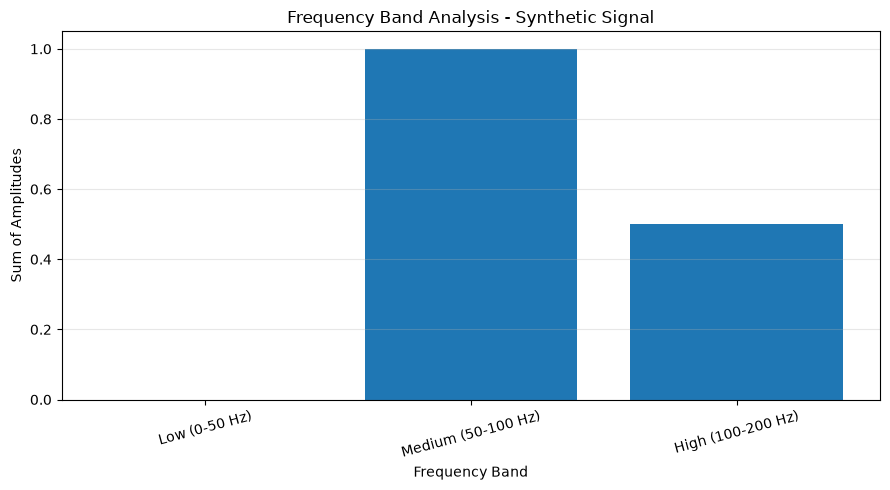

In [20]:

# Task 19: Visualize frequency band amplitudes

band_names = []
band_values = []

for band_name, (lower, upper) in frequency_bands.items():
    band_mask = (frequencies >= lower) & (frequencies < upper)

    band_names.append(band_name)
    band_values.append(amplitude[band_mask].sum())

plt.figure(figsize=(9, 5))
plt.bar(band_names, band_values)

plt.title("Frequency Band Analysis - Synthetic Signal")
plt.xlabel("Frequency Band")
plt.ylabel("Sum of Amplitudes")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()



## Task 20: Synthetic Frequency Band Analysis — Findings

### Objective
To practise FFT-based frequency analysis and understand how vibration signals can be grouped into frequency bands.

### Method
- Generated a synthetic vibration signal containing 50 Hz and 120 Hz.
- Used the Fast Fourier Transform (FFT) to identify frequency components.
- Grouped the frequency spectrum into low, medium, and high bands.
- Visualized the sum of amplitudes using a bar chart.

### Results
- Low band (0–50 Hz): 0.00
- Medium band (50–100 Hz): 1.00
- High band (100–200 Hz): 0.50

The 50 Hz component appeared in the medium band because the low band excludes its upper boundary. The 120 Hz component appeared in the high band.

### Conclusion
FFT successfully identified the two frequency components in the synthetic signal. This exercise demonstrates how frequency-band analysis works.

### Limitation
These results are from a synthetic signal, not actual sensor measurements. The available sensor CSV contains RMS summaries rather than confirmed raw waveform samples. Real sensor frequency-band analysis requires suitable waveform data and a documented sampling rate.


In [1]:

# Task 21: Check real sensor data for frequency analysis

import pandas as pd
from pathlib import Path

data_path = Path("../data/raw/1.csv")

df_check = pd.read_csv(data_path, sep=";")

print("Dataset shape:", df_check.shape)

print("\nAvailable columns:")
for column in df_check.columns:
    print("-", column)

print("\nVibration-related columns:")
for column in df_check.columns:
    if "accelerometer" in column.lower() or "vibration" in column.lower():
        print("-", column)

print("\nFirst five records:")
display(df_check.head())


Dataset shape: (1063, 11)

Available columns:
- datetime
- Accelerometer1RMS
- Accelerometer2RMS
- Current
- Pressure
- Temperature
- Thermocouple
- Voltage
- Volume Flow RateRMS
- anomaly
- changepoint

Vibration-related columns:
- Accelerometer1RMS
- Accelerometer2RMS

First five records:


,datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint
0,2020-03-09 16:16:30,0.027545,0.041127,0.673506,0.054711,67.8345,24.3164,240.513,32.0,0.0,0.0
1,2020-03-09 16:16:31,0.027997,0.039100,0.772264,0.054711,67.8704,24.3279,229.523,32.0,0.0,0.0
2,2020-03-09 16:16:32,0.028418,0.038872,0.675520,0.054711,67.7882,24.3261,242.708,32.0,0.0,0.0
3,2020-03-09 16:16:33,0.027625,0.039366,0.566279,-0.273216,67.7918,24.3323,229.709,32.0,0.0,0.0
4,2020-03-09 16:16:34,0.027484,0.041854,1.292170,0.054711,67.7368,24.3250,242.746,32.0,0.0,0.0


In [2]:

# Task 22: Analyze timestamp intervals in the real dataset

df_check["datetime"] = pd.to_datetime(
    df_check["datetime"], errors="coerce"
)

df_check = df_check.sort_values("datetime").reset_index(drop=True)

# Calculate time difference between consecutive records
df_check["time_interval_sec"] = (
    df_check["datetime"].diff().dt.total_seconds()
)

print("Total records:", len(df_check))
print("Invalid timestamps:", df_check["datetime"].isna().sum())
print("Duplicate timestamps:", df_check["datetime"].duplicated().sum())

print("\nTime interval counts (seconds):")
print(df_check["time_interval_sec"].value_counts().sort_index())

print("\nLargest time gaps:")
print(
    df_check.nlargest(5, "time_interval_sec")[
        ["datetime", "time_interval_sec"]
    ]
)


Total records: 1063
Invalid timestamps: 0
Duplicate timestamps: 0

Time interval counts (seconds):
time_interval_sec
1.0     986
2.0      75
64.0      1
Name: count, dtype: int64

Largest time gaps:
               datetime  time_interval_sec
838 2020-03-09 16:32:32               64.0
5   2020-03-09 16:16:36                2.0
20  2020-03-09 16:16:52                2.0
34  2020-03-09 16:17:07                2.0
48  2020-03-09 16:17:22                2.0


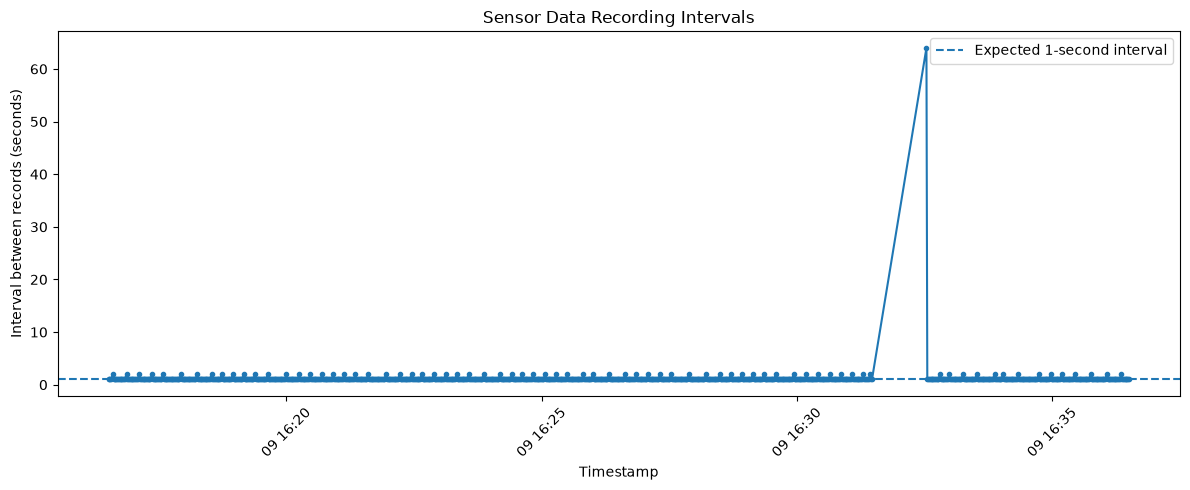

In [3]:

# Task 23: Visualize timestamp intervals

import matplotlib.pyplot as plt

intervals = df_check["time_interval_sec"].dropna()

plt.figure(figsize=(12, 5))
plt.plot(
    df_check["datetime"].iloc[1:],
    intervals,
    marker=".",
    linestyle="-"
)

plt.axhline(
    y=1,
    linestyle="--",
    label="Expected 1-second interval"
)

plt.xlabel("Timestamp")
plt.ylabel("Interval between records (seconds)")
plt.title("Sensor Data Recording Intervals")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Task 22–23: Timestamp Interval Analysis

**Objective:** To examine the time intervals between consecutive sensor readings and identify irregular recording gaps.

**Results:**
- Total records analyzed: 1,063
- Invalid timestamps: 0
- Duplicate timestamps: 0
- One-second intervals: 986
- Two-second intervals: 75
- Sixty-four-second intervals: 1

**Observation:** Most sensor readings are recorded at one-second intervals. However, one unusually large gap of 64 seconds was identified between `2020-03-09 16:31:28` and `2020-03-09 16:32:32`.

**Conclusion:** The dataset has mostly regular timestamps, with one significant recording gap that may indicate missing measurements or an interruption in data collection. Further investigation is needed to determine the cause.

**Limitation:** The timestamp intervals represent the record logging frequency, not the sensor's internal waveform sampling rate. Therefore, this dataset alone does not establish the sampling rate required for reliable real-world FFT frequency-band analysis.

In [4]:

# Task 25: Investigate the 64-second recording gap

# Find the record with the largest time interval
gap_index = df_check["time_interval_sec"].idxmax()

# Display 3 records before and 3 records after the gap
start_index = max(0, gap_index - 3)
end_index = min(len(df_check), gap_index + 4)

columns_to_check = [
    "datetime",
    "time_interval_sec",
    "Accelerometer1RMS",
    "Accelerometer2RMS",
    "Current",
    "Pressure",
    "Temperature",
    "anomaly"
]

print("Records around the largest time gap:")

display(
    df_check.loc[start_index:end_index - 1, columns_to_check]
)


Records around the largest time gap:


,datetime,time_interval_sec,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,anomaly
835,2020-03-09 16:31:26,2.0,0.027909,0.041702,0.765626,0.382638,68.8197,1.0
836,2020-03-09 16:31:27,1.0,0.027625,0.041403,0.817559,-0.273216,68.9544,1.0
837,2020-03-09 16:31:28,1.0,0.027886,0.040552,0.659105,0.054711,68.7719,1.0
838,2020-03-09 16:32:32,64.0,0.027447,0.040173,1.016950,0.054711,68.3797,1.0
839,2020-03-09 16:32:33,1.0,0.027411,0.040218,0.966904,0.710565,68.2498,1.0
840,2020-03-09 16:32:34,1.0,0.027269,0.040184,0.523052,0.382638,68.2564,1.0
841,2020-03-09 16:32:35,1.0,0.027585,0.039528,1.009490,0.382638,68.3120,1.0


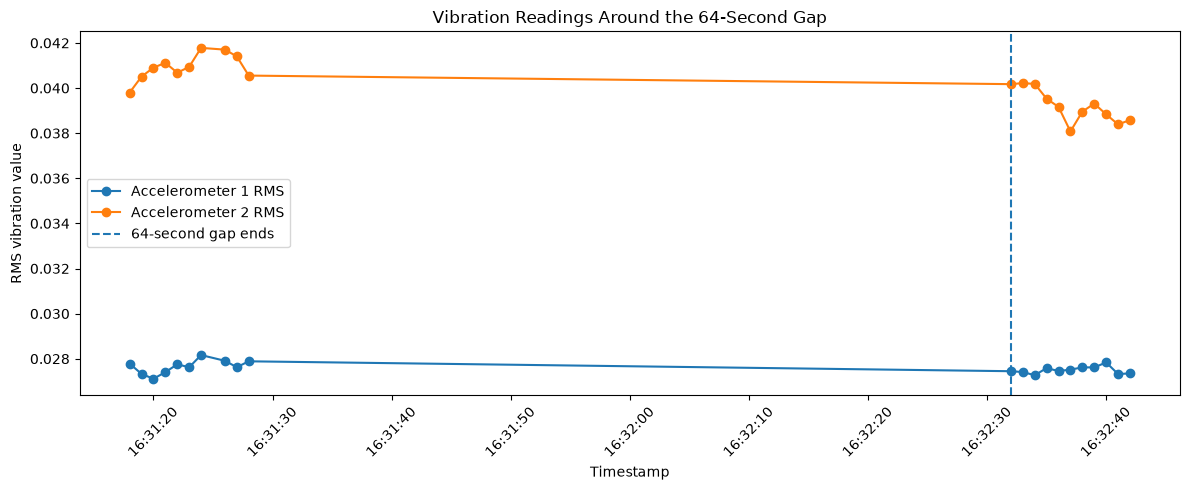

In [5]:

# Task 26: Visualize vibration around the recording gap

import matplotlib.pyplot as plt

gap_index = df_check["time_interval_sec"].idxmax()

start_index = max(0, gap_index - 10)
end_index = min(len(df_check), gap_index + 11)

gap_data = df_check.iloc[start_index:end_index].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    gap_data["datetime"],
    gap_data["Accelerometer1RMS"],
    marker="o",
    label="Accelerometer 1 RMS"
)

plt.plot(
    gap_data["datetime"],
    gap_data["Accelerometer2RMS"],
    marker="o",
    label="Accelerometer 2 RMS"
)

plt.axvline(
    df_check.loc[gap_index, "datetime"],
    linestyle="--",
    label="64-second gap ends"
)

plt.xlabel("Timestamp")
plt.ylabel("RMS vibration value")
plt.title("Vibration Readings Around the 64-Second Gap")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Task 26: Vibration Analysis Around the Recording Gap

**Objective:** To compare the two accelerometer RMS readings before and after the 64-second recording gap.

**Observations:**
- Accelerometer1RMS remains approximately within the 0.027–0.028 range.
- Accelerometer2RMS varies slightly before and after the gap.
- No obvious abrupt change is visible in the available readings at the gap boundaries.
- No measurements are available for the 64-second interval itself.

**Conclusion:** The available vibration RMS measurements appear relatively stable around the recording gap. However, the missing interval prevents us from determining whether any unusual vibration occurred during that period.

**Limitation:** RMS measurements summarize vibration magnitude and do not provide the raw waveform needed to identify individual frequency components. The graph connects points visually, so the connecting lines across the gap must not be interpreted as actual measurements.

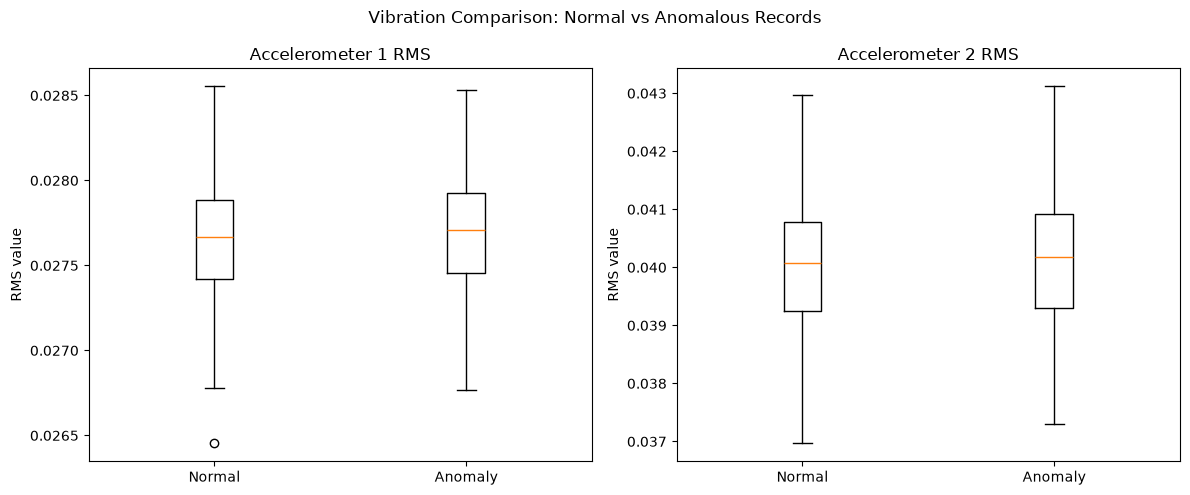

Normal records: 730
Anomalous records: 333


In [6]:

# Task 27: Compare vibration levels using box plots

import matplotlib.pyplot as plt

# Separate normal and anomalous records
normal = df_check[df_check["anomaly"] == 0]
anomalous = df_check[df_check["anomaly"] == 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Accelerometer 1
axes[0].boxplot(
    [
        normal["Accelerometer1RMS"].dropna(),
        anomalous["Accelerometer1RMS"].dropna()
    ],
    tick_labels=["Normal", "Anomaly"]
)
axes[0].set_title("Accelerometer 1 RMS")
axes[0].set_ylabel("RMS value")

# Accelerometer 2
axes[1].boxplot(
    [
        normal["Accelerometer2RMS"].dropna(),
        anomalous["Accelerometer2RMS"].dropna()
    ],
    tick_labels=["Normal", "Anomaly"]
)
axes[1].set_title("Accelerometer 2 RMS")
axes[1].set_ylabel("RMS value")

fig.suptitle("Vibration Comparison: Normal vs Anomalous Records")
plt.tight_layout()
plt.show()

print("Normal records:", len(normal))
print("Anomalous records:", len(anomalous))


### Task 27: Vibration Comparison Using Box Plots

**Objective:** To compare the distributions of Accelerometer1RMS and Accelerometer2RMS between normal and anomalous records.

**Dataset groups:**
- Normal records: 730
- Anomalous records: 333

**Observations:**
1. Accelerometer1RMS has a slightly higher median in anomalous records.
2. Accelerometer2RMS also has a slightly higher median in anomalous records.
3. Both sensors show substantial overlap between the normal and anomalous distributions.
4. One low outlier is visible for Accelerometer1RMS in the normal group.

**Conclusion:** The box plots suggest that vibration RMS magnitude alone does not clearly distinguish normal records from anomalous records. Further analysis using additional sensor features or suitable frequency-domain data may help identify more informative patterns.

**Limitation:** These comparisons describe associations in the available dataset and do not establish the cause of anomalies. The dataset contains RMS summaries rather than confirmed raw waveform samples, limiting real-world FFT frequency-band analysis.

In [7]:

# Task 28: Statistical comparison of vibration readings

import pandas as pd

# Select vibration columns
vibration_columns = [
    "Accelerometer1RMS",
    "Accelerometer2RMS"
]

# Calculate statistics for normal and anomalous records
statistics = df_check.groupby("anomaly")[vibration_columns].agg(
    ["mean", "median", "std"]
)

# Display the results
print("Vibration Statistics: Normal (0) vs Anomaly (1)")
display(statistics)

# Calculate the difference between group means
normal_means = df_check[df_check["anomaly"] == 0][vibration_columns].mean()
anomaly_means = df_check[df_check["anomaly"] == 1][vibration_columns].mean()

mean_comparison = pd.DataFrame({
    "Normal Mean": normal_means,
    "Anomaly Mean": anomaly_means,
    "Mean Difference": anomaly_means - normal_means
})

print("\nMean Comparison:")
display(mean_comparison)


Vibration Statistics: Normal (0) vs Anomaly (1)


Accelerometer1RMS                     Accelerometer2RMS            \
                     mean    median       std              mean    median   
anomaly                                                                     
0.0              0.027650  0.027667  0.000335          0.040007  0.040074   
1.0              0.027692  0.027707  0.000329          0.040102  0.040173   

                   
              std  
anomaly            
0.0      0.001054  
1.0      0.001152


Mean Comparison:


,Normal Mean,Anomaly Mean,Mean Difference
Accelerometer1RMS,0.027650,0.027692,0.000042
Accelerometer2RMS,0.040007,0.040102,0.000095


### Task 28: Statistical Analysis of Vibration Readings

**Objective:** To compare the mean, median, and standard deviation of two accelerometer RMS measurements between normal and anomalous records.

**Results:**

- Accelerometer1RMS mean: 0.027650 for normal records and 0.027692 for anomalous records.
- Accelerometer2RMS mean: 0.040007 for normal records and 0.040102 for anomalous records.
- The mean differences are 0.000042 and 0.000095, respectively.
- Accelerometer2RMS has a slightly higher standard deviation in anomalous records.

**Conclusion:** Both accelerometer RMS means are slightly higher in anomalous records. However, the differences are small, and the distributions overlap substantially. RMS magnitude alone may not be sufficient to identify anomalies reliably.

**Limitation:** These results describe the available dataset and do not establish causation or statistical significance. Further investigation using additional sensor features and suitable raw waveform data may be necessary.

In [8]:

# Task 29: Calculate percentage difference in mean vibration

normal_means = df_check[
    df_check["anomaly"] == 0
][["Accelerometer1RMS", "Accelerometer2RMS"]].mean()

anomaly_means = df_check[
    df_check["anomaly"] == 1
][["Accelerometer1RMS", "Accelerometer2RMS"]].mean()

percentage_difference = (
    (anomaly_means - normal_means)
    / normal_means
) * 100

result = pd.DataFrame({
    "Normal Mean": normal_means,
    "Anomaly Mean": anomaly_means,
    "Percentage Difference (%)": percentage_difference
})

display(result)


,Normal Mean,Anomaly Mean,Percentage Difference (%)
Accelerometer1RMS,0.027650,0.027692,0.151102
Accelerometer2RMS,0.040007,0.040102,0.236504


### Task 29: Percentage Difference in Mean Vibration

**Objective:** To quantify the relative difference in average vibration between normal and anomalous records.

**Results:**
- Accelerometer1RMS shows a 0.1511% increase in the anomalous group.
- Accelerometer2RMS shows a 0.2365% increase in the anomalous group.

**Conclusion:** Both accelerometers have slightly higher mean RMS values in anomalous records. Accelerometer2RMS has the larger relative increase, but the differences are small. Further analysis is needed before concluding whether these measurements are useful for anomaly detection.

**Limitation:** These percentages describe differences between group averages. They do not establish statistical significance or prove that vibration changes cause anomalies.

In [9]:

# Task 30: Mann–Whitney U test

from scipy.stats import mannwhitneyu

sensors = ["Accelerometer1RMS", "Accelerometer2RMS"]

for sensor in sensors:
    normal_values = df_check.loc[
        df_check["anomaly"] == 0, sensor
    ].dropna()

    anomaly_values = df_check.loc[
        df_check["anomaly"] == 1, sensor
    ].dropna()

    statistic, p_value = mannwhitneyu(
        normal_values,
        anomaly_values,
        alternative="two-sided"
    )

    print(f"\nSensor: {sensor}")
    print(f"Mann-Whitney U statistic: {statistic:.3f}")
    print(f"P-value: {p_value:.6f}")

    if p_value < 0.05:
        print("Result: Evidence of a distributional difference.")
    else:
        print("Result: Insufficient evidence of a distributional difference.")



Sensor: Accelerometer1RMS
Mann-Whitney U statistic: 114222.500
P-value: 0.114767
Result: Insufficient evidence of a distributional difference.

Sensor: Accelerometer2RMS
Mann-Whitney U statistic: 116055.000
P-value: 0.237042
Result: Insufficient evidence of a distributional difference.


### Task 30: Mann–Whitney U Test for Vibration Readings

**Objective:** To test whether vibration RMS distributions differ between normal and anomalous records.

**Hypotheses:**
- **Null hypothesis (H₀):** The vibration-value distributions are the same in the two groups.
- **Alternative hypothesis (H₁):** The vibration-value distributions differ between the two groups.

**Significance level:** 0.05

**Results:**
- Accelerometer1RMS: U = 114222.500, p = 0.114767.
- Accelerometer2RMS: U = 116055.000, p = 0.237042.

**Conclusion:** Both p-values exceed 0.05. Therefore, the tests do not provide sufficient evidence to reject the null hypothesis for either sensor.

**Limitation:** The Mann–Whitney U test compares group distributions; it does not directly measure anomaly-detection accuracy. The time-series nature of the data may also violate the assumption that observations are independent. Further validation is needed before drawing conclusions about anomaly detection performance.

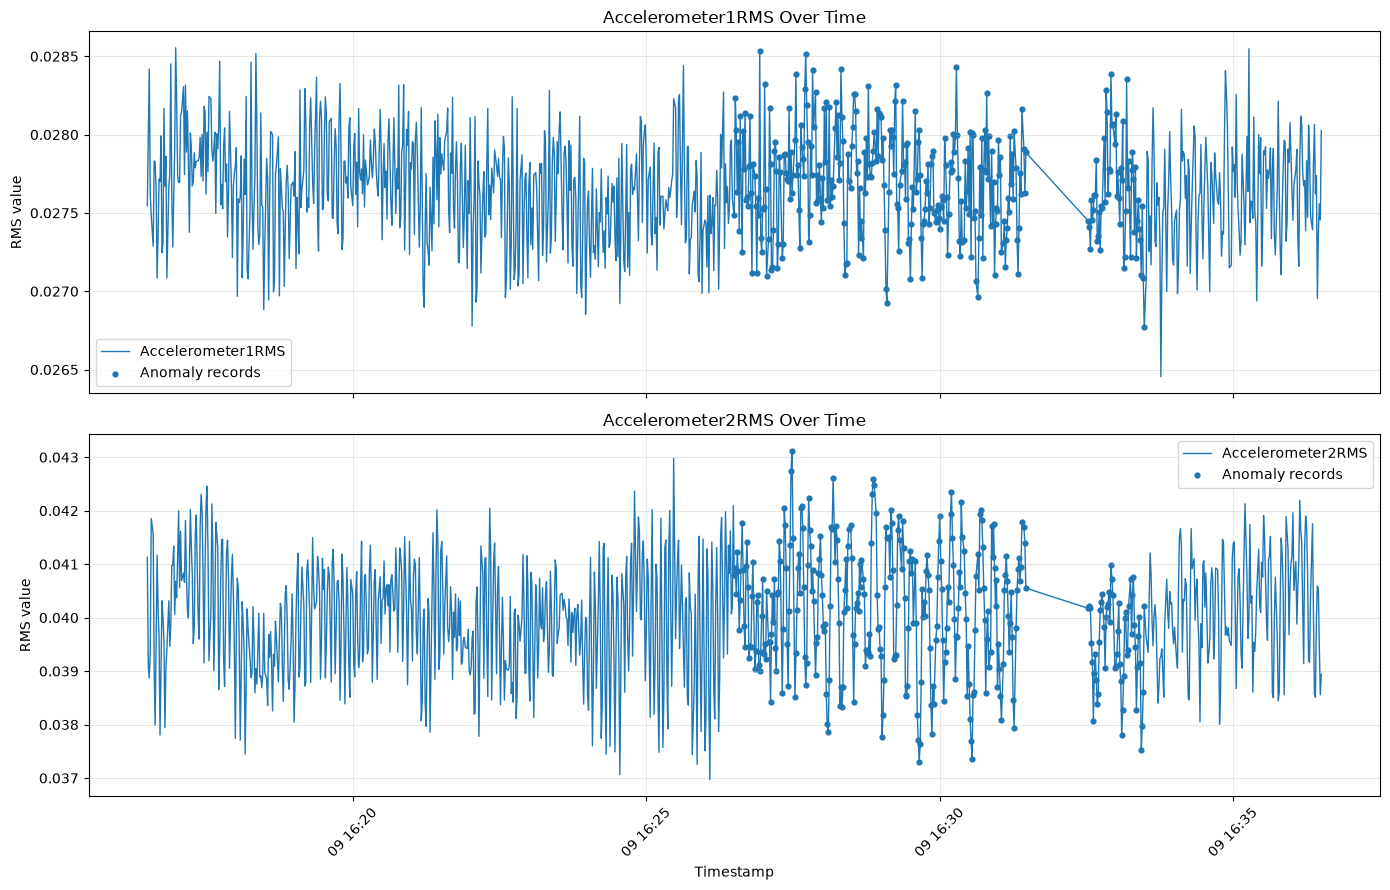

In [10]:

# Task 31: Vibration readings over time with anomaly labels

import matplotlib.pyplot as plt

# Keep records with valid timestamps
plot_df = df_check.dropna(subset=["datetime"]).copy()
plot_df = plot_df.sort_values("datetime")

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

sensors = ["Accelerometer1RMS", "Accelerometer2RMS"]

for ax, sensor in zip(axes, sensors):
    ax.plot(
        plot_df["datetime"],
        plot_df[sensor],
        label=sensor,
        linewidth=1
    )

    # Highlight anomalous readings
    anomaly_df = plot_df[plot_df["anomaly"] == 1]

    ax.scatter(
        anomaly_df["datetime"],
        anomaly_df[sensor],
        label="Anomaly records",
        s=12
    )

    ax.set_ylabel("RMS value")
    ax.set_title(f"{sensor} Over Time")
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Timestamp")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


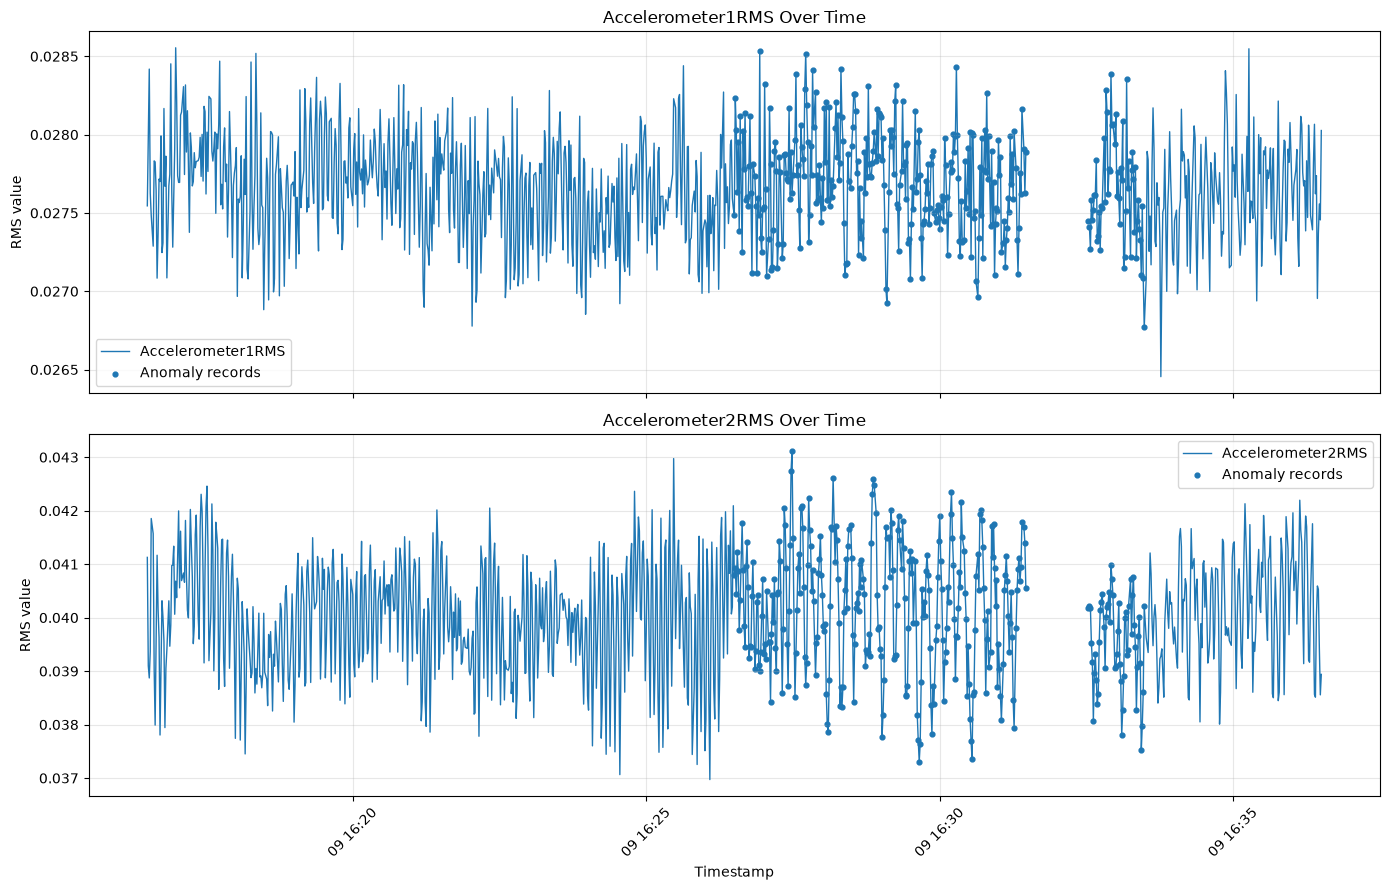

In [11]:

# Task 32: Plot vibration readings without connecting large time gaps

import matplotlib.pyplot as plt
import numpy as np

plot_df = df_check.sort_values("datetime").copy()

# Break lines at gaps longer than 2 seconds
gap_mask = plot_df["time_interval_sec"] > 2

sensors = ["Accelerometer1RMS", "Accelerometer2RMS"]

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

for ax, sensor in zip(axes, sensors):
    # Create a line that breaks at large gaps
    line_values = plot_df[sensor].astype(float).copy()
    line_values.loc[gap_mask] = np.nan

    ax.plot(
        plot_df["datetime"],
        line_values,
        label=sensor,
        linewidth=1
    )

    anomaly_df = plot_df[plot_df["anomaly"] == 1]

    ax.scatter(
        anomaly_df["datetime"],
        anomaly_df[sensor],
        label="Anomaly records",
        s=12
    )

    ax.set_title(f"{sensor} Over Time")
    ax.set_ylabel("RMS value")
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Timestamp")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Task 31–32: Vibration Time-Series Analysis

**Objective:** To visualize accelerometer RMS measurements over time, identify patterns in anomaly-labeled records, and avoid connecting measurements across large recording gaps.

**Observations:**
1. Accelerometer1RMS fluctuates mainly around 0.027–0.0285.
2. Accelerometer2RMS fluctuates approximately between 0.037 and 0.043.
3. Anomaly-labeled records appear in clusters during parts of the recording.
4. No obvious, sustained increase in vibration magnitude is visible throughout the anomalous periods.
5. A 64-second recording gap exists, and the plot must not imply continuous measurements during this interval.

**Conclusion:** The time-series plots show variation in both vibration measurements, but RMS magnitude alone does not clearly distinguish anomalous records from normal records.

**Limitation:** The anomaly labels identify records flagged by the dataset; they do not establish the physical cause of an anomaly. The available RMS measurements also do not provide the raw waveform required for reliable real-world FFT frequency-band analysis.

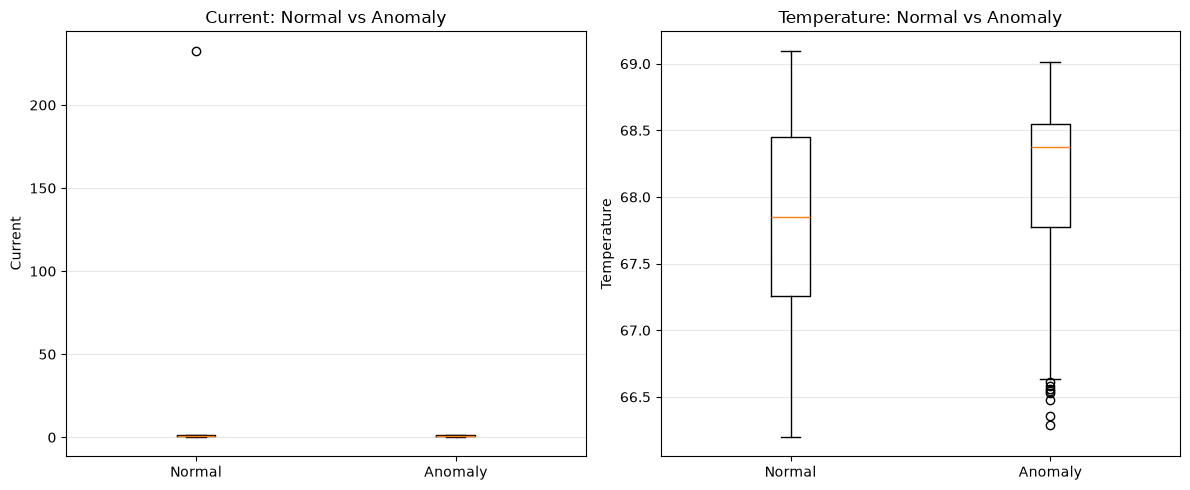

Current                     Temperature                   
             mean    median       std        mean   median       std
anomaly                                                             
0.0      1.304793  1.030210  8.581618   67.779661  67.8525  0.715543
1.0      0.955078  0.973761  0.264527   68.148399  68.3733  0.572781

In [12]:

# Task 34: Compare Current and Temperature by anomaly label

import matplotlib.pyplot as plt

sensors = ["Current", "Temperature"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, sensor in zip(axes, sensors):
    normal_values = df_check.loc[
        df_check["anomaly"] == 0, sensor
    ].dropna()

    anomaly_values = df_check.loc[
        df_check["anomaly"] == 1, sensor
    ].dropna()

    ax.boxplot(
        [normal_values, anomaly_values],
        tick_labels=["Normal", "Anomaly"]
    )

    ax.set_title(f"{sensor}: Normal vs Anomaly")
    ax.set_ylabel(sensor)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Compare group statistics
comparison = df_check.groupby("anomaly")[sensors].agg(
    ["mean", "median", "std"]
)

display(comparison)


### Task 34: Current and Temperature Comparison

**Objective:** To compare Current and Temperature measurements between normal and anomalous records using box plots and descriptive statistics.

**Observations:**
1. Current has an extreme value of 232.734 in the normal group, which substantially affects its mean.
2. The median Current reading is slightly lower in the anomalous group.
3. The median Temperature is 68.3733 in the anomalous group and 67.8525 in the normal group.
4. The anomalous group's mean Temperature is also higher than the normal group's mean.

**Conclusion:** Temperature shows a clearer difference in central values between the two groups than the Current median does. Temperature may be worth investigating as a potential anomaly-related feature. However, these descriptive results alone do not establish statistical significance or predictive usefulness.

**Limitation:** The extreme Current reading should be investigated before deciding how to handle it. Differences between group summaries do not establish causation or anomaly-detection performance.

In [13]:

# Task 35: Statistical test for Current and Temperature

from scipy.stats import mannwhitneyu

for sensor in ["Current", "Temperature"]:
    normal_values = df_check.loc[
        df_check["anomaly"] == 0, sensor
    ].dropna()

    anomaly_values = df_check.loc[
        df_check["anomaly"] == 1, sensor
    ].dropna()

    statistic, p_value = mannwhitneyu(
        normal_values,
        anomaly_values,
        alternative="two-sided"
    )

    print(f"\nSensor: {sensor}")
    print(f"Mann-Whitney U statistic: {statistic:.3f}")
    print(f"P-value: {p_value:.6f}")

    if p_value < 0.05:
        print("Result: Evidence of a distributional difference.")
    else:
        print("Result: Insufficient evidence of a distributional difference.")



Sensor: Current
Mann-Whitney U statistic: 130083.000
P-value: 0.065924
Result: Insufficient evidence of a distributional difference.

Sensor: Temperature
Mann-Whitney U statistic: 87131.500
P-value: 0.000000
Result: Evidence of a distributional difference.


### Task 35: Mann–Whitney U Test for Current and Temperature

**Objective:** To evaluate whether Current and Temperature distributions differ between normal and anomalous records.

**Significance level:** 0.05

**Results:**
- Current: U = 130083.000, p = 0.065924.
- Temperature: U = 87131.500, p is less than 0.000001 based on the displayed rounded output.

**Conclusion:**
1. Current: The test does not provide sufficient evidence to reject the null hypothesis.
2. Temperature: The test provides strong evidence of a distributional difference between normal and anomalous records.

Temperature may be a useful feature for further anomaly analysis. However, statistical significance alone does not establish causation or predictive accuracy.

**Limitation:** The observations form a time series, so neighboring records may not be independent. Further validation is needed before using Temperature as an anomaly-detection feature.

In [14]:

# Task 36: Compare temperature effect size

normal_temp = df_check.loc[
    df_check["anomaly"] == 0, "Temperature"
].dropna()

anomaly_temp = df_check.loc[
    df_check["anomaly"] == 1, "Temperature"
].dropna()

normal_median = normal_temp.median()
anomaly_median = anomaly_temp.median()

median_difference = anomaly_median - normal_median

print(f"Normal median temperature: {normal_median:.4f}")
print(f"Anomaly median temperature: {anomaly_median:.4f}")
print(f"Median difference: {median_difference:.4f}")

percentage_difference = (
    median_difference / normal_median
) * 100

print(f"Percentage difference: {percentage_difference:.4f}%")


Normal median temperature: 67.8525
Anomaly median temperature: 68.3733
Median difference: 0.5208
Percentage difference: 0.7675%


### Task 36: Temperature Difference and Effect Size

**Objective:** To quantify the difference in median temperature between normal and anomalous records.

**Results:**
- Normal median temperature: 67.8525
- Anomaly median temperature: 68.3733
- Median difference: 0.5208
- Percentage difference relative to the normal median: 0.7675%

**Conclusion:** The anomalous group has a higher median temperature than the normal group. This finding, together with the Mann–Whitney U test, indicates an association between temperature and anomaly labels in this dataset.

**Limitation:** The percentage difference describes the relative change in medians; it is not a standardized statistical effect size. Further validation is needed to determine whether temperature can reliably support anomaly detection.

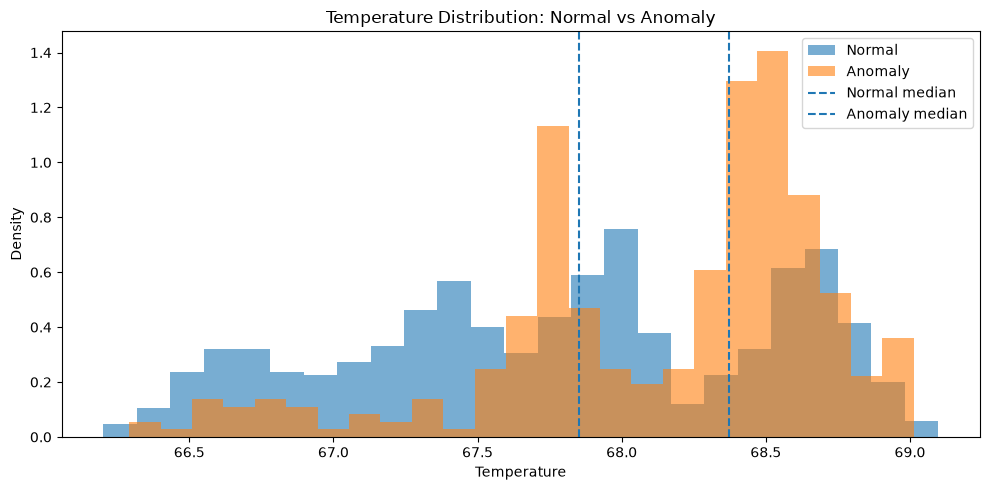

In [15]:

# Task 37: Temperature distribution comparison

import matplotlib.pyplot as plt

normal_temp = df_check.loc[
    df_check["anomaly"] == 0, "Temperature"
].dropna()

anomaly_temp = df_check.loc[
    df_check["anomaly"] == 1, "Temperature"
].dropna()

plt.figure(figsize=(10, 5))

plt.hist(
    normal_temp,
    bins=25,
    alpha=0.6,
    label="Normal",
    density=True
)

plt.hist(
    anomaly_temp,
    bins=25,
    alpha=0.6,
    label="Anomaly",
    density=True
)

plt.axvline(
    normal_temp.median(),
    linestyle="--",
    label="Normal median"
)

plt.axvline(
    anomaly_temp.median(),
    linestyle="--",
    label="Anomaly median"
)

plt.xlabel("Temperature")
plt.ylabel("Density")
plt.title("Temperature Distribution: Normal vs Anomaly")
plt.legend()
plt.tight_layout()
plt.show()


### Task 37: Temperature Distribution Visualization

**Objective:** To compare the temperature distributions of normal and anomalous records using overlapping histograms.

**Observations:**
1. The normal median temperature is 67.8525.
2. The anomalous median temperature is 68.3733.
3. The anomalous distribution has a higher median and a noticeable concentration around 68.4–68.6.
4. The two distributions overlap substantially.

**Conclusion:** Temperature distributions differ between the two groups, consistent with the Mann–Whitney U test result. However, the overlap indicates that temperature alone may not reliably distinguish every anomalous record from every normal record.

**Limitation:** This visualization describes the dataset's existing anomaly labels. It does not establish causation or demonstrate predictive performance on unseen data.

Normal Current mean, including extreme value: 1.304793
Normal Current mean, excluding extreme value: 0.987332
Normal Current median: 1.03021
Anomaly Current median: 0.973761


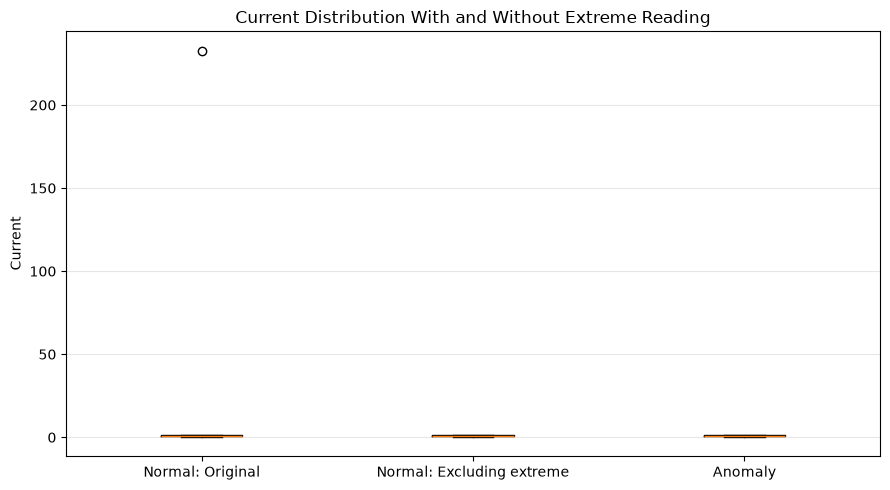

In [16]:

# Task 39: Investigate the extreme Current reading

current_outlier = 232.734

normal_current = df_check.loc[
    df_check["anomaly"] == 0, "Current"
].dropna()

# Exclude the extreme value only for this comparison
normal_current_without_outlier = normal_current[
    normal_current != current_outlier
]

anomaly_current = df_check.loc[
    df_check["anomaly"] == 1, "Current"
].dropna()

print("Normal Current mean, including extreme value:",
      round(normal_current.mean(), 6))

print("Normal Current mean, excluding extreme value:",
      round(normal_current_without_outlier.mean(), 6))

print("Normal Current median:",
      round(normal_current.median(), 6))

print("Anomaly Current median:",
      round(anomaly_current.median(), 6))

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        normal_current,
        normal_current_without_outlier,
        anomaly_current
    ],
    tick_labels=[
        "Normal: Original",
        "Normal: Excluding extreme",
        "Anomaly"
    ]
)

plt.ylabel("Current")
plt.title("Current Distribution With and Without Extreme Reading")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Task 39: Investigation of the Extreme Current Reading

**Objective:** To examine how an extreme Current reading affects the descriptive statistics and visualization.

**Results:**
- Normal Current mean including the extreme reading: 1.304793.
- Normal Current mean excluding the extreme reading: 0.987332.
- Normal Current median: 1.030210.
- Anomaly Current median: 0.973761.

**Observations:** The extreme Current reading of 232.734 substantially increases the normal group's mean. Excluding it for a comparison reduces the mean considerably, while the median remains unchanged.

**Conclusion:** The mean is sensitive to extreme observations, whereas the median is more robust. The extreme reading should be investigated before deciding whether it represents a genuine event or a data-quality issue.

**Limitation:** Excluding the reading was only a comparison exercise. The original dataset remains unchanged, and the observation should not be removed from the analysis without a justified reason.

In [17]:

# Task 40: Inspect the extreme Current reading

outlier_index = df_check["Current"].idxmax()

columns_to_check = [
    "datetime",
    "Current",
    "Voltage",
    "Temperature",
    "Pressure",
    "Accelerometer1RMS",
    "Accelerometer2RMS",
    "anomaly",
    "changepoint"
]

print("Record containing the maximum Current reading:")
display(df_check.loc[[outlier_index], columns_to_check])

print("\nNearby records:")
start = max(0, outlier_index - 3)
end = min(len(df_check), outlier_index + 4)

display(df_check.loc[start:end - 1, columns_to_check])


Record containing the maximum Current reading:


,datetime,Current,Voltage,Temperature,Pressure,Accelerometer1RMS,Accelerometer2RMS,anomaly,changepoint
1002,2020-03-09 16:35:27,232.734,0.580776,67.3543,0.382638,0.02775,0.040226,0.0,0.0



Nearby records:


,datetime,Current,Voltage,Temperature,Pressure,Accelerometer1RMS,Accelerometer2RMS,anomaly,changepoint
999,2020-03-09 16:35:23,0.595224,222.273000,67.3363,0.054711,0.027439,0.039756,0.0,0.0
1000,2020-03-09 16:35:24,0.791495,220.399000,67.4203,0.054711,0.026938,0.040510,0.0,0.0
1001,2020-03-09 16:35:26,0.994151,234.827000,67.4138,0.054711,0.028000,0.041276,0.0,0.0
1002,2020-03-09 16:35:27,232.734000,0.580776,67.3543,0.382638,0.027750,0.040226,0.0,0.0
1003,2020-03-09 16:35:28,0.731046,232.680000,67.2731,-0.273216,0.027981,0.040096,0.0,0.0
1004,2020-03-09 16:35:29,0.459507,206.043000,67.3535,0.382638,0.027160,0.041035,0.0,0.0
1005,2020-03-09 16:35:30,0.497475,234.426000,67.3706,0.054711,0.027375,0.040758,0.0,0.0


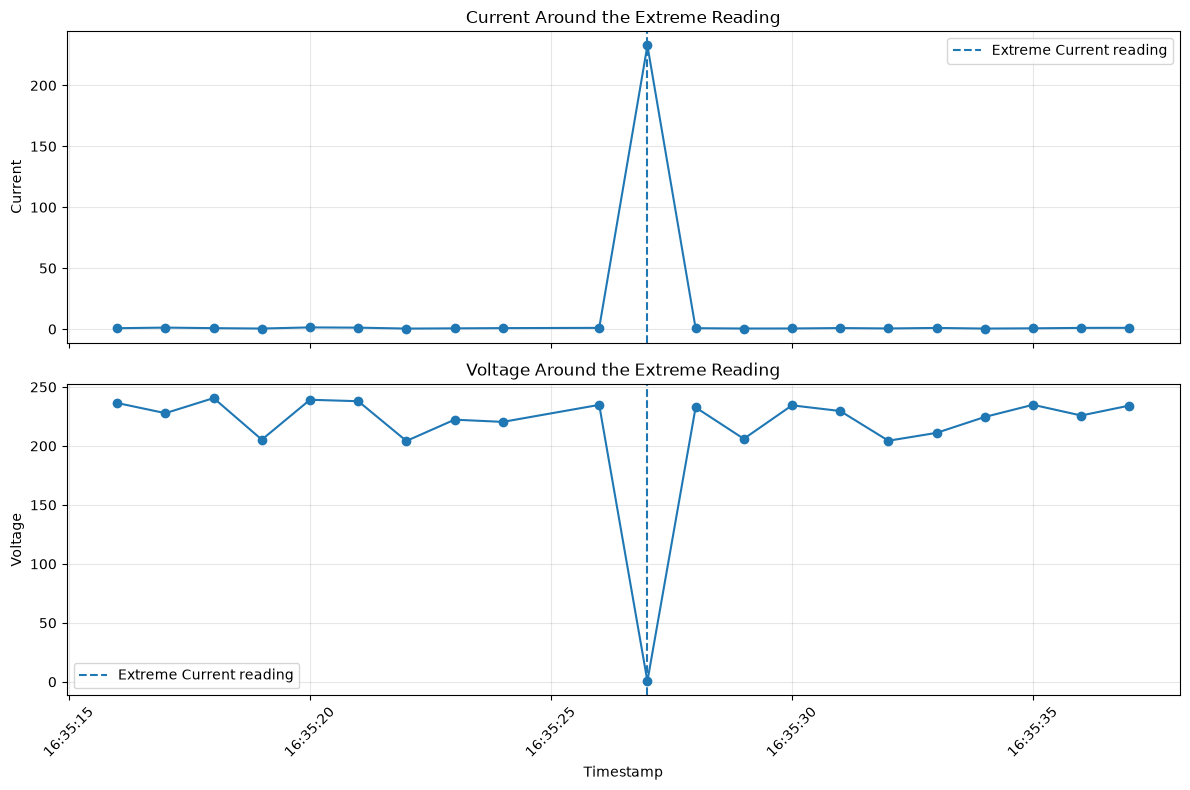

In [18]:

# Task 41: Plot Current and Voltage around the extreme reading

import matplotlib.pyplot as plt

outlier_index = df_check["Current"].idxmax()

start = max(0, outlier_index - 10)
end = min(len(df_check), outlier_index + 11)

event_data = df_check.iloc[start:end].copy()

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(
    event_data["datetime"],
    event_data["Current"],
    marker="o"
)
axes[0].axvline(
    df_check.loc[outlier_index, "datetime"],
    linestyle="--",
    label="Extreme Current reading"
)
axes[0].set_ylabel("Current")
axes[0].set_title("Current Around the Extreme Reading")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    event_data["datetime"],
    event_data["Voltage"],
    marker="o"
)
axes[1].axvline(
    df_check.loc[outlier_index, "datetime"],
    linestyle="--",
    label="Extreme Current reading"
)
axes[1].set_ylabel("Voltage")
axes[1].set_xlabel("Timestamp")
axes[1].set_title("Voltage Around the Extreme Reading")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Task 41: Current and Voltage Around the Extreme Reading

**Objective:** To investigate an extreme Current reading and examine the corresponding Voltage behavior.

**Event timestamp:** 2020-03-09 16:35:27

**Observations:**
1. Current rises sharply to 232.734.
2. Voltage drops sharply to 0.580776 at the same timestamp.
3. In the next recorded row, Current returns to 0.731046 and Voltage returns to 232.680.
4. Both anomaly and changepoint labels are 0 for the event.
5. The accelerometer RMS readings remain within their usual ranges.

**Conclusion:** The simultaneous Current spike and Voltage drop represent an unusual, isolated event that warrants further investigation.

**Limitation:** The available dataset does not establish the physical cause of this event. The original record is retained, and no values have been deleted or modified.

In [19]:

# Task 42: Current-Voltage correlation sensitivity check

current_voltage = df_check[["Current", "Voltage"]].dropna()

# Correlation using all records
correlation_all = current_voltage["Current"].corr(
    current_voltage["Voltage"]
)

# Exclude the extreme Current record for comparison only
correlation_without_extreme = current_voltage[
    current_voltage["Current"] != 232.734
]["Current"].corr(
    current_voltage[
        current_voltage["Current"] != 232.734
    ]["Voltage"]
)

print(f"Correlation including extreme record: {correlation_all:.4f}")
print(
    "Correlation excluding extreme record: "
    f"{correlation_without_extreme:.4f}"
)


Correlation including extreme record: -0.5200
Correlation excluding extreme record: 0.3309


### Task 42: Current–Voltage Correlation Sensitivity Analysis

**Objective:** To investigate how an extreme Current reading affects the Pearson correlation between Current and Voltage.

**Results:**
- Correlation including the extreme record: −0.5200.
- Correlation excluding the extreme record: +0.3309.

**Observations:** The correlation changes from negative to positive when the extreme Current record is excluded for comparison. This indicates that the overall linear relationship is sensitive to that observation.

**Conclusion:** Extreme observations can substantially influence correlation analysis. Both results should be reported transparently, and the unusual record should be investigated before deciding how it should be handled.

**Limitation:** Correlation does not establish causation. Excluding a record for sensitivity analysis does not justify deleting it from the original dataset.

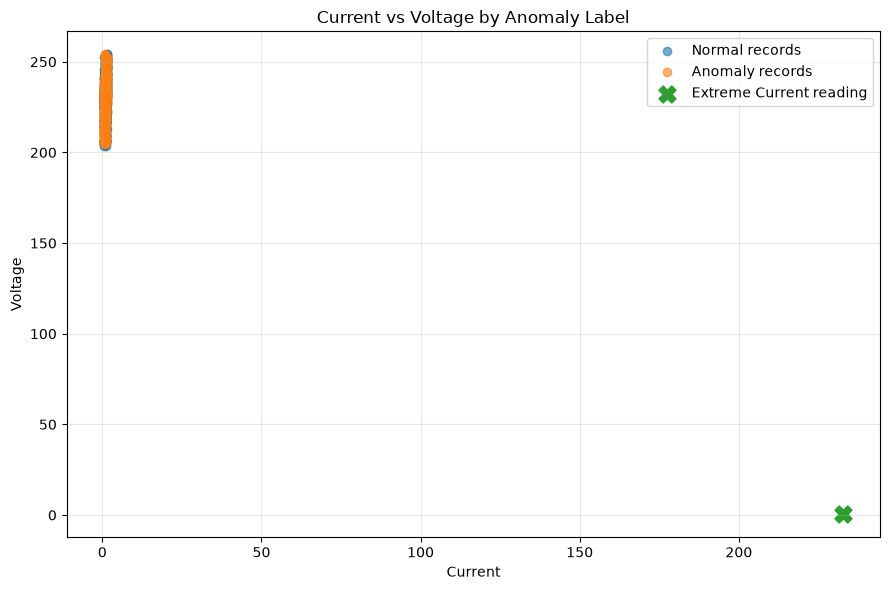

In [20]:

# Task 43: Current vs Voltage scatter plot

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

normal_records = df_check[df_check["anomaly"] == 0]
anomaly_records = df_check[df_check["anomaly"] == 1]

plt.scatter(
    normal_records["Current"],
    normal_records["Voltage"],
    alpha=0.6,
    label="Normal records"
)

plt.scatter(
    anomaly_records["Current"],
    anomaly_records["Voltage"],
    alpha=0.6,
    label="Anomaly records"
)

# Highlight the extreme Current reading
outlier = df_check.loc[df_check["Current"].idxmax()]

plt.scatter(
    outlier["Current"],
    outlier["Voltage"],
    marker="X",
    s=150,
    label="Extreme Current reading"
)

plt.xlabel("Current")
plt.ylabel("Voltage")
plt.title("Current vs Voltage by Anomaly Label")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


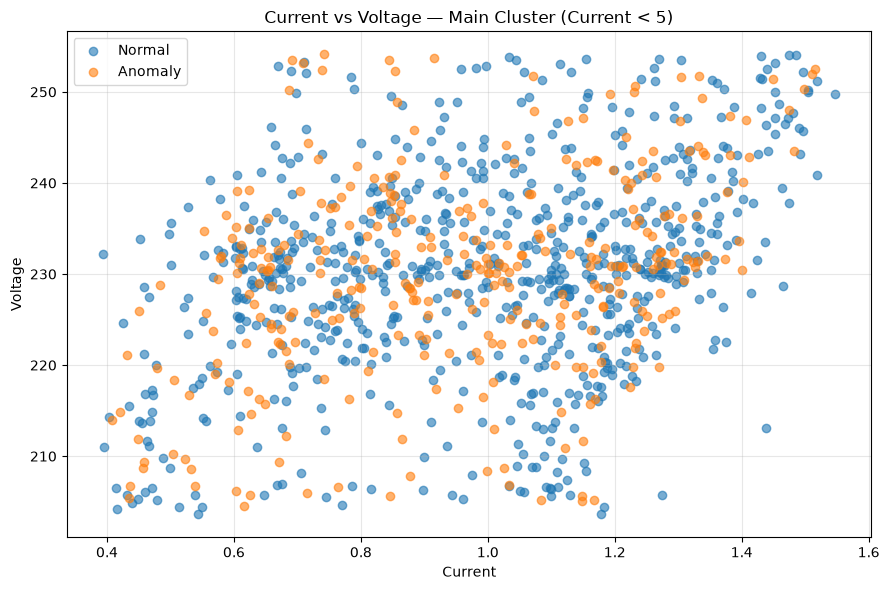

Records in main cluster: 1062
Records excluded from this view: 1


In [21]:

# Task 44: Zoom in on the main Current-Voltage cluster

main_cluster = df_check[
    (df_check["Current"] < 5) &
    (df_check["Current"] >= 0)
]

plt.figure(figsize=(9, 6))

for label, name in [(0, "Normal"), (1, "Anomaly")]:
    group = main_cluster[main_cluster["anomaly"] == label]

    plt.scatter(
        group["Current"],
        group["Voltage"],
        alpha=0.6,
        label=name
    )

plt.xlabel("Current")
plt.ylabel("Voltage")
plt.title("Current vs Voltage — Main Cluster (Current < 5)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Records in main cluster:", len(main_cluster))
print("Records excluded from this view:", len(df_check) - len(main_cluster))


### Task 44: Zoomed-In Current–Voltage Scatter Plot

**Objective:** To visualize the main cluster of Current and Voltage measurements without allowing the extreme Current reading to compress the plot.

**Observations:**
1. The visualization contains 1,062 records with Current below 5 and at least 0.
2. One extreme Current record is excluded from this view only.
3. Normal and anomalous records overlap substantially.
4. Voltage values vary considerably across the observed Current range.

**Conclusion:** The zoomed-in scatter plot improves visibility of the main data cluster but does not show a clear separation between normal and anomalous records.

**Limitation:** The plot is a visualization filter, not a modification of the original dataset. The excluded record remains important for further investigation.


In [22]:

# Task 45: Correlation within the main Current cluster

main_cluster = df_check[
    (df_check["Current"] >= 0) &
    (df_check["Current"] < 5)
]

correlation_main = main_cluster["Current"].corr(
    main_cluster["Voltage"]
)

print("Records in main cluster:", len(main_cluster))
print(
    "Current-Voltage correlation in main cluster:",
    round(correlation_main, 4)
)

print("\nCorrelation by anomaly label:")

for label, name in [(0, "Normal"), (1, "Anomaly")]:
    group = main_cluster[main_cluster["anomaly"] == label]

    correlation = group["Current"].corr(group["Voltage"])

    print(f"{name}: {correlation:.4f}")


Records in main cluster: 1062
Current-Voltage correlation in main cluster: 0.3309

Correlation by anomaly label:
Normal: 0.3262
Anomaly: 0.3408


### Task 45: Current–Voltage Correlation in the Main Cluster

**Objective:** To evaluate the Current–Voltage linear relationship after excluding the extreme Current reading for comparison.

**Results:**
- Main cluster correlation: +0.3309
- Normal records correlation: +0.3262
- Anomalous records correlation: +0.3408

**Observations:** The main cluster shows a positive linear association between Current and Voltage. Correlations for normal and anomalous records are similar, and their scatter plots overlap substantially.

**Conclusion:** The extreme Current reading strongly influences the full-dataset correlation. Within the main cluster, Current–Voltage correlation alone does not clearly distinguish normal from anomalous records.

**Limitation:** Excluding the extreme reading is a sensitivity analysis, not a decision to remove it from the original dataset. Correlation does not establish causation or predictive performance.

In [23]:

# Task 46: Summary of key EDA findings

print("===== SENSOR TELEMETRY EDA SUMMARY =====")

print("\n1. Dataset")
print("Total records:", len(df_check))
print("Normal records:", (df_check["anomaly"] == 0).sum())
print("Anomalous records:", (df_check["anomaly"] == 1).sum())

print("\n2. Recording intervals")
print(df_check["time_interval_sec"].value_counts().sort_index())

print("\n3. Vibration")
print("Accelerometer RMS distributions overlap between groups.")
print("Mann-Whitney tests did not show significant differences.")

print("\n4. Temperature")
print("Normal median:", round(
    df_check.loc[df_check["anomaly"] == 0, "Temperature"].median(), 4
))
print("Anomaly median:", round(
    df_check.loc[df_check["anomaly"] == 1, "Temperature"].median(), 4
))
print("Temperature test p-value was below 0.05.")

print("\n5. Extreme Current reading")
print("Maximum Current:", df_check["Current"].max())
print("Timestamp:", df_check.loc[df_check["Current"].idxmax(), "datetime"])

print("\n6. Frequency analysis limitation")
print("Available accelerometer columns contain RMS summaries.")
print("Raw high-frequency waveform samples and sampling-rate metadata")
print("are not available in the inspected dataset.")


===== SENSOR TELEMETRY EDA SUMMARY =====

1. Dataset
Total records: 1063
Normal records: 730
Anomalous records: 333

2. Recording intervals
time_interval_sec
1.0     986
2.0      75
64.0      1
Name: count, dtype: int64

3. Vibration
Accelerometer RMS distributions overlap between groups.
Mann-Whitney tests did not show significant differences.

4. Temperature
Normal median: 67.8525
Anomaly median: 68.3733
Temperature test p-value was below 0.05.

5. Extreme Current reading
Maximum Current: 232.734
Timestamp: 2020-03-09 16:35:27

6. Frequency analysis limitation
Available accelerometer columns contain RMS summaries.
Raw high-frequency waveform samples and sampling-rate metadata
are not available in the inspected dataset.


# Sensor Telemetry EDA — Key Findings and Limitations

## 1. Dataset Overview
- Total records: 1,063
- Normal records: 730
- Anomalous records: 333
- Invalid timestamps: 0
- Duplicate timestamps: 0

## 2. Recording Interval Analysis
- 986 intervals are 1 second.
- 75 intervals are 2 seconds.
- One interval is 64 seconds.
- The 64-second gap indicates a discontinuity in the recorded timeline.

## 3. Vibration Analysis
- Accelerometer1RMS and Accelerometer2RMS distributions overlap substantially between normal and anomalous records.
- Mann–Whitney U tests did not show statistically significant distributional differences for either accelerometer.
- RMS magnitude alone does not clearly distinguish the two groups.

## 4. Temperature Analysis
- Normal median: 67.8525
- Anomaly median: 68.3733
- Median difference: 0.5208
- The Mann–Whitney U test indicated a statistically significant distributional difference.
- The distributions still overlap, so further validation is necessary.

## 5. Current and Voltage Investigation
- Maximum Current: 232.734 at 2020-03-09 16:35:27.
- Voltage at that timestamp: 0.580776.
- The record is labeled normal in the dataset.
- The extreme observation changes the Current–Voltage correlation from −0.5200 to +0.3309 when excluded for sensitivity analysis.
- The original observation has been retained.

## 6. Frequency-Band Analysis Limitation
The available accelerometer measurements are RMS summaries. Raw high-frequency waveform samples and documented sensor sampling-rate metadata were not identified in the inspected dataset.

Synthetic FFT analysis was performed to practice frequency extraction and frequency-band aggregation. These synthetic results do not represent measured frequency components of the real sensor data.

## Overall Conclusion
The EDA identified a recording gap, an extreme Current–Voltage observation, and a statistically significant temperature distributional difference between normal and anomalous records. The available RMS data does not support reconstructing the original vibration waveform or performing a reliable real-data FFT frequency-band analysis.

Further work requires suitable raw waveform data, sampling-rate information, and validation of any proposed anomaly-detection features.


In [1]:

import pandas as pd
from pathlib import Path

# Locate the project data folder
data_folder = Path("../data/raw")

# Find CSV files
csv_files = list(data_folder.glob("*.csv"))

print("CSV files found:", csv_files)

# Inspect each CSV file
for file in csv_files:
    print("\nFile:", file.name)

    # Our raw dataset uses semicolons
    df = pd.read_csv(file, sep=";")

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nFirst 5 rows:")
    print(df.head())

    print("\nData types:")
    print(df.dtypes)


CSV files found: [WindowsPath('../data/raw/1.csv')]

File: 1.csv
Shape: (1063, 11)
Columns: ['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']

First 5 rows:
              datetime  Accelerometer1RMS  Accelerometer2RMS   Current  \
0  2020-03-09 16:16:30           0.027545           0.041127  0.673506   
1  2020-03-09 16:16:31           0.027997           0.039100  0.772264   
2  2020-03-09 16:16:32           0.028418           0.038872  0.675520   
3  2020-03-09 16:16:33           0.027625           0.039366  0.566279   
4  2020-03-09 16:16:34           0.027484           0.041854  1.292170   

   Pressure  Temperature  Thermocouple  Voltage  Volume Flow RateRMS  anomaly  \
0  0.054711      67.8345       24.3164  240.513                 32.0      0.0   
1  0.054711      67.8704       24.3279  229.523                 32.0      0.0   
2  0.054711      67.7882       24.32

In [2]:

import pandas as pd

df = pd.read_csv("../data/raw/1.csv", sep=";")

print("1. Dataset columns:")
for column in df.columns:
    print("-", column)

print("\n2. Number of unique values in each sensor column:")
sensor_columns = [
    "Accelerometer1RMS",
    "Accelerometer2RMS",
    "Current",
    "Pressure",
    "Temperature",
    "Thermocouple",
    "Voltage",
    "Volume Flow RateRMS"
]

print(df[sensor_columns].nunique())

print("\n3. Timestamp intervals:")
df["datetime"] = pd.to_datetime(df["datetime"])
intervals = df["datetime"].sort_values().diff().dt.total_seconds()

print(intervals.value_counts().sort_index())

print("\n4. Sampling information:")
print("Timestamp interval values:", sorted(intervals.dropna().unique()))
print("Raw waveform column available: No clearly identified raw waveform column")
print("Sensor sampling rate documented in this CSV: Not found")


1. Dataset columns:
- datetime
- Accelerometer1RMS
- Accelerometer2RMS
- Current
- Pressure
- Temperature
- Thermocouple
- Voltage
- Volume Flow RateRMS
- anomaly
- changepoint

2. Number of unique values in each sensor column:
Accelerometer1RMS      1021
Accelerometer2RMS      1046
Current                1061
Pressure                  7
Temperature            1034
Thermocouple            571
Voltage                1050
Volume Flow RateRMS      71
dtype: int64

3. Timestamp intervals:
datetime
1.0     986
2.0      75
64.0      1
Name: count, dtype: int64

4. Sampling information:
Timestamp interval values: [np.float64(1.0), np.float64(2.0), np.float64(64.0)]
Raw waveform column available: No clearly identified raw waveform column
Sensor sampling rate documented in this CSV: Not found


In [3]:

from pathlib import Path

# Search the project's data folder and its subfolders
data_folder = Path("../data")

print("Files available in the project data folder:\n")

for file in sorted(data_folder.rglob("*")):
    if file.is_file():
        print(f"{file} | {file.stat().st_size} bytes")


Files available in the project data folder:

..\data\clean\sensor_data_clean.csv | 110614 bytes
..\data\raw\1.csv | 123334 bytes


In [4]:

import pandas as pd

# Load both datasets
raw_df = pd.read_csv("../data/raw/1.csv", sep=";")
clean_df = pd.read_csv("../data/clean/sensor_data_clean.csv")

print("===== RAW DATASET =====")
print("Shape:", raw_df.shape)
print("Columns:", raw_df.columns.tolist())

print("\n===== CLEANED DATASET =====")
print("Shape:", clean_df.shape)
print("Columns:", clean_df.columns.tolist())

print("\n===== COLUMN COMPARISON =====")
raw_columns = set(raw_df.columns)
clean_columns = set(clean_df.columns)

print("Columns only in raw dataset:",
      sorted(raw_columns - clean_columns))

print("Columns only in cleaned dataset:",
      sorted(clean_columns - raw_columns))

print("\n===== CLEANED DATA PREVIEW =====")
print(clean_df.head().to_string(index=False))


===== RAW DATASET =====
Shape: (1063, 11)
Columns: ['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']

===== CLEANED DATASET =====
Shape: (1063, 11)
Columns: ['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']

===== COLUMN COMPARISON =====
Columns only in raw dataset: []
Columns only in cleaned dataset: []

===== CLEANED DATA PREVIEW =====
           datetime  Accelerometer1RMS  Accelerometer2RMS  Current  Pressure  Temperature  Thermocouple  Voltage  Volume Flow RateRMS  anomaly  changepoint
2020-03-09 16:16:30           0.027545           0.041127 0.673506  0.054711      67.8345       24.3164  240.513                 32.0      0.0          0.0
2020-03-09 16:16:31           0.027997           0.039100 0.772264  0.054711      67.8704       24.3279  229.5

In [5]:

import pandas as pd

raw_df = pd.read_csv("../data/raw/1.csv", sep=";")
clean_df = pd.read_csv("../data/clean/sensor_data_clean.csv")

checks = {
    "Check": [
        "Same number of records",
        "Same columns",
        "Raw waveform samples available",
        "Sampling rate documented",
        "Anomaly labels available"
    ],
    "Result": [
        len(raw_df) == len(clean_df),
        set(raw_df.columns) == set(clean_df.columns),
        False,
        False,
        "anomaly" in clean_df.columns
    ],
    "Meaning": [
        "Both datasets contain the same number of records",
        "No additional columns in the cleaned dataset",
        "No clearly identified raw waveform data",
        "Sampling rate must be obtained from another source",
        "Normal and anomalous records can be compared"
    ]
}

evidence = pd.DataFrame(checks)
print(evidence.to_string(index=False))


                         Check  Result                                            Meaning
        Same number of records    True   Both datasets contain the same number of records
                  Same columns    True       No additional columns in the cleaned dataset
Raw waveform samples available   False            No clearly identified raw waveform data
      Sampling rate documented   False Sampling rate must be obtained from another source
      Anomaly labels available    True       Normal and anomalous records can be compared


In [6]:

from pathlib import Path

data_folder = Path("../data/waveform")

print("Does waveform folder exist?", data_folder.exists())

if data_folder.exists():
    files = [p for p in data_folder.rglob("*") if p.is_file()]

    print("Total files found:", len(files))
    print("\nFirst 30 files:")

    for file in files[:30]:
        print(f"{file} | {file.stat().st_size:,} bytes")
else:
    print("Please place the extracted NASA dataset inside data/waveform.")


Does waveform folder exist? True
Total files found: 1

First 30 files:
..\data\waveform\2004.04.17.23.32.55 | 553,987 bytes


In [7]:

from pathlib import Path

file_path = Path("../data/waveform/2004.04.17.23.32.55")

print("File exists:", file_path.exists())
print("File size:", file_path.stat().st_size, "bytes")

# Display the first 10 lines without modifying the file
with open(file_path, "r", encoding="utf-8", errors="replace") as file:
    for line_number in range(10):
        line = file.readline()
        if not line:
            break
        print(f"Line {line_number + 1}: {line.rstrip()}")


File exists: True
File size: 553987 bytes
Line 1: 0.117	-0.244	0.156	-0.100
Line 2: 0.068	0.034	0.305	0.195
Line 3: 0.066	0.469	0.308	0.151
Line 4: 0.237	0.471	-0.286	-0.103
Line 5: 0.149	0.049	0.078	-0.247
Line 6: 0.078	-0.186	0.205	-0.068
Line 7: 0.186	0.007	0.188	0.112
Line 8: 0.166	0.181	0.151	0.164
Line 9: 0.012	0.120	0.325	0.100
Line 10: -0.098	0.103	-0.203	-0.117


In [8]:

import pandas as pd
import numpy as np
from pathlib import Path

# Load the vibration file (tab-separated, no header)
file_path = Path("../data/waveform/2004.04.17.23.32.55")

vibration_df = pd.read_csv(
    file_path,
    sep="\t",
    header=None
)

print("Dataset shape:", vibration_df.shape)
print("\nFirst 5 rows:")
print(vibration_df.head())

print("\nMissing values:", vibration_df.isnull().sum().sum())
print("\nData types:")
print(vibration_df.dtypes)

# Check the signal length
print("\nNumber of samples per channel:", len(vibration_df))

# Sampling rate documented for the NASA IMS dataset
sampling_rate = 20480
print("Sampling rate used:", sampling_rate, "Hz")
print("Duration per channel:", len(vibration_df) / sampling_rate, "seconds")


Dataset shape: (20480, 4)

First 5 rows:
       0      1      2      3
0  0.117 -0.244  0.156 -0.100
1  0.068  0.034  0.305  0.195
2  0.066  0.469  0.308  0.151
3  0.237  0.471 -0.286 -0.103
4  0.149  0.049  0.078 -0.247

Missing values: 0

Data types:
0    float64
1    float64
2    float64
3    float64
dtype: object

Number of samples per channel: 20480
Sampling rate used: 20480 Hz
Duration per channel: 1.0 seconds


Samples: 20480
Sampling rate: 20480 Hz
Frequency resolution: 1.0 Hz
Strongest non-zero frequency: 1185.0 Hz
Amplitude at peak: 0.039273494518516465


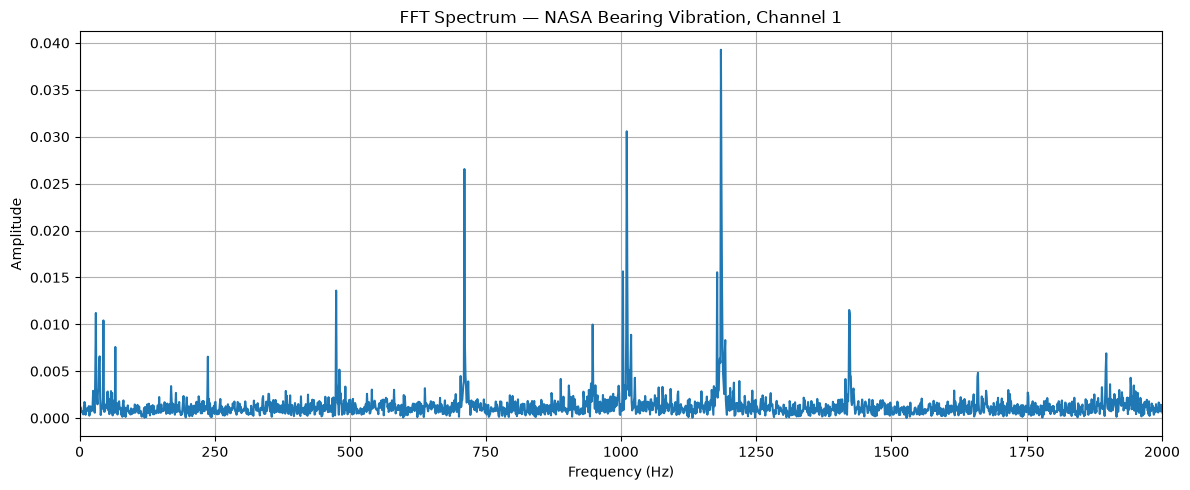

In [9]:

import numpy as np
import matplotlib.pyplot as plt

# Select the first vibration channel
signal = vibration_df[0].to_numpy()

# Sampling frequency in Hz, based on the dataset documentation
sampling_rate = 20480

# Remove the mean to focus on vibration fluctuations
signal_centered = signal - np.mean(signal)

# Calculate FFT
fft_values = np.fft.rfft(signal_centered)
frequencies = np.fft.rfftfreq(
    len(signal_centered),
    d=1 / sampling_rate
)

# Calculate single-sided amplitude spectrum
amplitude = 2 * np.abs(fft_values) / len(signal_centered)
amplitude[0] /= 2

if len(signal_centered) % 2 == 0:
    amplitude[-1] /= 2

# Find the strongest frequency, excluding zero frequency
peak_index = np.argmax(amplitude[1:]) + 1

print("Samples:", len(signal))
print("Sampling rate:", sampling_rate, "Hz")
print("Frequency resolution:", sampling_rate / len(signal), "Hz")
print("Strongest non-zero frequency:", frequencies[peak_index], "Hz")
print("Amplitude at peak:", amplitude[peak_index])

# Plot frequency spectrum up to 2,000 Hz
plt.figure(figsize=(12, 5))
plt.plot(frequencies, amplitude)
plt.xlim(0, 2000)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("FFT Spectrum — NASA Bearing Vibration, Channel 1")
plt.grid(True)
plt.tight_layout()
plt.show()


Frequency Band Analysis
      Frequency Band Frequency Range (Hz)  Band Energy (amplitude²)
      Low (0–500 Hz)                0–500                  0.001372
Medium (500–1000 Hz)             500–1000                  0.001860
 High (1000–2000 Hz)            1000–2000                  0.006740


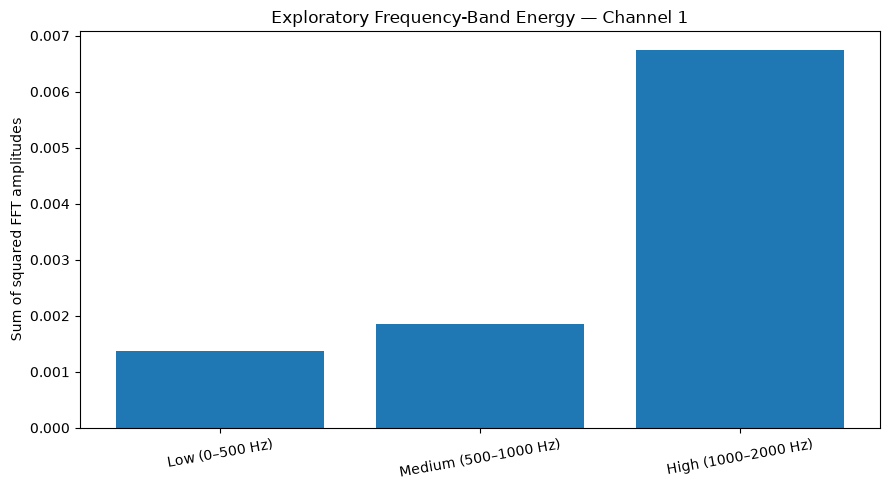

In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the FFT amplitude spectrum calculated earlier
bands = {
    "Low (0–500 Hz)": (0, 500),
    "Medium (500–1000 Hz)": (500, 1000),
    "High (1000–2000 Hz)": (1000, 2000)
}

results = []

for band_name, (lower, upper) in bands.items():
    mask = (frequencies >= lower) & (frequencies < upper)

    # Sum squared amplitudes as an exploratory band-energy measure
    band_energy = np.sum(amplitude[mask] ** 2)

    results.append({
        "Frequency Band": band_name,
        "Frequency Range (Hz)": f"{lower}–{upper}",
        "Band Energy (amplitude²)": band_energy
    })

band_df = pd.DataFrame(results)

print("Frequency Band Analysis")
print(band_df.to_string(index=False))

# Visualize band energy
plt.figure(figsize=(9, 5))
plt.bar(band_df["Frequency Band"], band_df["Band Energy (amplitude²)"])
plt.ylabel("Sum of squared FFT amplitudes")
plt.title("Exploratory Frequency-Band Energy — Channel 1")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


In [11]:

import numpy as np
import pandas as pd

sampling_rate = 20480

bands = {
    "Low (0–500 Hz)": (0, 500),
    "Medium (500–1000 Hz)": (500, 1000),
    "High (1000–2000 Hz)": (1000, 2000)
}

channel_results = []

for channel in vibration_df.columns:
    signal = vibration_df[channel].to_numpy(dtype=float)
    signal = signal - np.mean(signal)

    fft_values = np.fft.rfft(signal)
    frequencies = np.fft.rfftfreq(
        len(signal), d=1 / sampling_rate
    )

    amplitude = 2 * np.abs(fft_values) / len(signal)
    amplitude[0] /= 2

    if len(signal) % 2 == 0:
        amplitude[-1] /= 2

    row = {"Channel": f"Channel {channel + 1}"}

    for band_name, (low, high) in bands.items():
        mask = (frequencies >= low) & (frequencies < high)
        row[band_name] = np.sum(amplitude[mask] ** 2)

    channel_results.append(row)

channel_band_df = pd.DataFrame(channel_results)

print("Frequency-band comparison across channels:")
print(channel_band_df.to_string(index=False))


Frequency-band comparison across channels:
  Channel  Low (0–500 Hz)  Medium (500–1000 Hz)  High (1000–2000 Hz)
Channel 1        0.001372              0.001860             0.006740
Channel 2        0.003044              0.004199             0.007274
Channel 3        0.010918              0.011157             0.012788
Channel 4        0.001524              0.001084             0.001707


In [12]:

# Copy the existing frequency-band comparison
percentage_df = channel_band_df.copy()

band_columns = [
    "Low (0–500 Hz)",
    "Medium (500–1000 Hz)",
    "High (1000–2000 Hz)"
]

# Calculate each band's percentage of the channel's total
for column in band_columns:
    percentage_df[column] = (
        channel_band_df[column]
        / channel_band_df[band_columns].sum(axis=1)
        * 100
    )

print("Normalized Frequency-Band Energy (%)")
print(percentage_df.round(2).to_string(index=False))


Normalized Frequency-Band Energy (%)
  Channel  Low (0–500 Hz)  Medium (500–1000 Hz)  High (1000–2000 Hz)
Channel 1           13.76                 18.65                67.59
Channel 2           20.97                 28.93                50.10
Channel 3           31.32                 32.00                36.68
Channel 4           35.32                 25.12                39.57


### Frequency-Band Analysis — Key Findings

**Dataset:** NASA IMS bearing vibration snapshot  
**Sampling rate:** 20,480 Hz  
**Samples per channel:** 20,480  
**Signal duration:** 1 second  
**Channels analyzed:** 4

**Method:** The mean was removed from each signal, and the real FFT was calculated. The frequency spectrum was divided into three exploratory bands: low (0–500 Hz), medium (500–1,000 Hz), and high (1,000–2,000 Hz). Summed squared FFT amplitudes were calculated for each band and normalized to percentages within each channel.

**Findings:**
- Channel 1 had the largest relative high-band contribution, approximately 67.59%.
- Channel 2 also showed high-band dominance at approximately 50.10%.
- Channel 3 had a more balanced distribution, with approximately 31.32% low-band, 32.00% medium-band, and 36.68% high-band energy.
- Channel 4 had approximately 35.32% low-band, 25.12% medium-band, and 39.56% high-band energy.

**Conclusion:** The four channels have different frequency-energy distributions in this recording. These results establish a baseline for further exploratory analysis.

**Limitations:** This analysis covers only one vibration snapshot. The selected frequency bands are exploratory, not validated fault-frequency ranges. The observed spectral differences alone do not establish bearing health or failure. Further analysis requires multiple recordings, confirmed operating conditions, sensor metadata, and suitable healthy/faulty reference labels.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Folder containing NASA vibration recordings
data_folder = (
    Path.home()
    / "Downloads"
    / "NASA_Bearing_Extracted"
    / "1st_test"
    / "1st_test"
)

# Select five recordings
files = sorted(data_folder.iterdir())[:5]

print("Number of recordings selected:", len(files))

for file in files:
    print(file.name, file.stat().st_size, "bytes")

Number of recordings selected: 5
2003.10.22.12.06.24 1148716 bytes
2003.10.22.12.09.13 1149141 bytes
2003.10.22.12.14.13 1149766 bytes
2003.10.22.12.19.13 1149168 bytes
2003.10.22.12.24.13 1149152 bytes


Frequency-band energy comparison:


,Recording,Samples,Low (0–500 Hz),Medium (500–1000 Hz),High (1000–2000 Hz)
0,2003.10.22.12.06.24,20480,0.000420,0.000735,0.004614
1,2003.10.22.12.09.13,20480,0.000417,0.000720,0.004428
2,2003.10.22.12.14.13,20480,0.000404,0.000699,0.004564
3,2003.10.22.12.19.13,20480,0.000388,0.000771,0.004528
4,2003.10.22.12.24.13,20480,0.000438,0.000689,0.004603


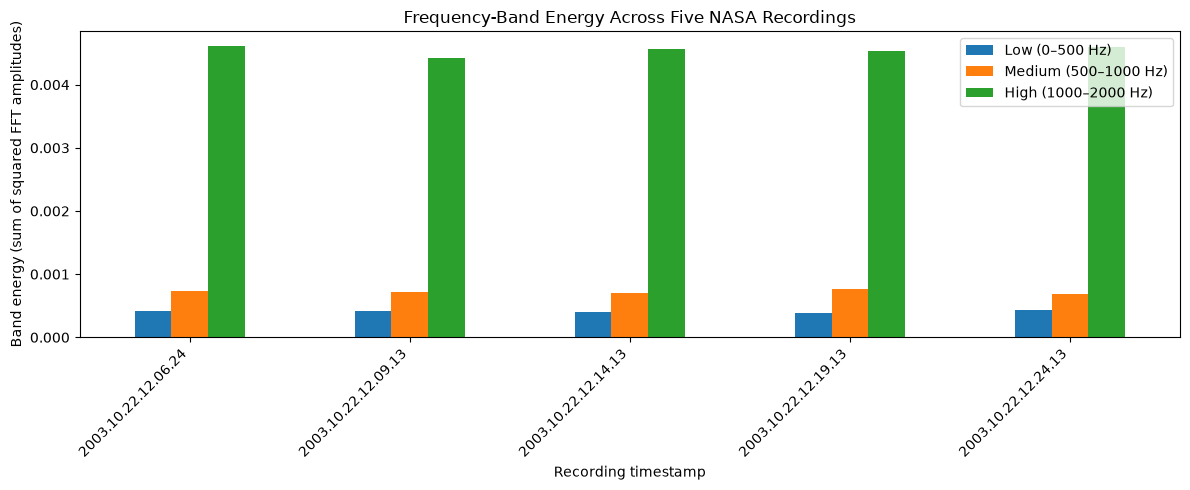

In [2]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# NASA recording folder
data_folder = (
    Path.home()
    / "Downloads"
    / "NASA_Bearing_Extracted"
    / "1st_test"
    / "1st_test"
)

# Sampling rate: 20,480 samples per second
sampling_rate = 20480

# Select five recordings
files = sorted(data_folder.iterdir())[:5]

results = []

for file in files:
    # Load the four vibration channels
    df = pd.read_csv(file, sep=r"\s+", header=None)

    # Analyze Channel 1
    signal = df[0].to_numpy(dtype=float)
    signal = signal - np.mean(signal)

    # Calculate FFT
    fft_values = np.fft.rfft(signal)
    frequencies = np.fft.rfftfreq(
        len(signal), d=1 / sampling_rate
    )
    amplitude = 2 * np.abs(fft_values) / len(signal)
    amplitude[0] /= 2

    if len(signal) % 2 == 0:
        amplitude[-1] /= 2

    # Calculate energy in each frequency band
    bands = {
        "Low (0–500 Hz)": (0, 500),
        "Medium (500–1000 Hz)": (500, 1000),
        "High (1000–2000 Hz)": (1000, 2000),
    }

    row = {
        "Recording": file.name,
        "Samples": len(signal),
    }

    for band_name, (low, high) in bands.items():
        mask = (frequencies >= low) & (frequencies < high)
        row[band_name] = np.sum(amplitude[mask] ** 2)

    results.append(row)

# Display comparison table
results_df = pd.DataFrame(results)

print("Frequency-band energy comparison:")
display(results_df.round(6))

# Plot frequency-band energy across recordings
plot_df = results_df.set_index("Recording")[
    list(bands.keys())
]

plot_df.plot(kind="bar", figsize=(12, 5))
plt.title("Frequency-Band Energy Across Five NASA Recordings")
plt.xlabel("Recording timestamp")
plt.ylabel("Band energy (sum of squared FFT amplitudes)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [4]:

from pathlib import Path
import numpy as np
import pandas as pd

data_folder = (
    Path.home()
    / "Downloads"
    / "NASA_Bearing_Extracted"
    / "1st_test"
    / "1st_test"
)

sampling_rate = 20480
files = sorted(data_folder.iterdir())[:5]

bands = {
    "Low (0–500 Hz)": (0, 500),
    "Medium (500–1000 Hz)": (500, 1000),
    "High (1000–2000 Hz)": (1000, 2000),
}

results = []

for file in files:
    df = pd.read_csv(file, sep=r"\s+", header=None)

    for channel in range(4):
        signal = df[channel].to_numpy(dtype=float)
        signal = signal - np.mean(signal)

        fft_values = np.fft.rfft(signal)
        frequencies = np.fft.rfftfreq(
            len(signal), d=1 / sampling_rate
        )
        amplitude = 2 * np.abs(fft_values) / len(signal)
        amplitude[0] /= 2

        if len(signal) % 2 == 0:
            amplitude[-1] /= 2

        row = {
            "Recording": file.name,
            "Channel": f"Channel {channel + 1}",
        }

        for band_name, (low, high) in bands.items():
            mask = (frequencies >= low) & (frequencies < high)
            row[band_name] = np.sum(amplitude[mask] ** 2)

        results.append(row)

channel_results = pd.DataFrame(results)

display(channel_results.round(6))


,Recording,Channel,Low (0–500 Hz),Medium (500–1000 Hz),High (1000–2000 Hz)
0,2003.10.22.12.06.24,Channel 1,0.000420,0.000735,0.004614
1,2003.10.22.12.06.24,Channel 2,0.000438,0.000552,0.002593
2,2003.10.22.12.06.24,Channel 3,0.000720,0.001654,0.006529
3,2003.10.22.12.06.24,Channel 4,0.000992,0.001308,0.003956
4,2003.10.22.12.09.13,Channel 1,0.000417,0.000720,0.004428
5,2003.10.22.12.09.13,Channel 2,0.000457,0.000589,0.002469
6,2003.10.22.12.09.13,Channel 3,0.000810,0.001601,0.006408
7,2003.10.22.12.09.13,Channel 4,0.000969,0.001139,0.003918
8,2003.10.22.12.14.13,Channel 1,0.000404,0.000699,0.004564
9,2003.10.22.12.14.13,Channel 2,0.000453,0.000559,0.002659


### Frequency-Band Energy Comparison Across Four Vibration Channels

**Objective:** To compare low-, medium-, and high-frequency energy across four vibration channels using five NASA bearing vibration recordings.

**Methodology:**
1. Loaded five vibration recordings.
2. Analyzed all four channels in each recording.
3. Applied the Fast Fourier Transform (FFT) to convert time-domain signals into the frequency domain.
4. Calculated energy in three exploratory frequency bands: low (0–500 Hz), medium (500–1000 Hz), and high (1000–2000 Hz).
5. Compared the energy values across channels and recording timestamps.

**Observations:**
- The high-frequency band has the greatest energy across all four channels in the selected recordings.
- Channel 3 shows the highest high-frequency energy.
- Channel 4 shows the highest low-frequency energy.
- Small variations occur across recording timestamps.

**Conclusion:**

The analysis shows that vibration energy is distributed differently across frequency bands and sensor channels. The high-frequency band dominates the selected recordings. Further analysis using more recordings and verified bearing-condition labels is required before drawing conclusions about bearing faults or degradation.

**Limitation:** The frequency bands are exploratory and are not validated fault-detection thresholds. Energy differences alone do not confirm a bearing fault.

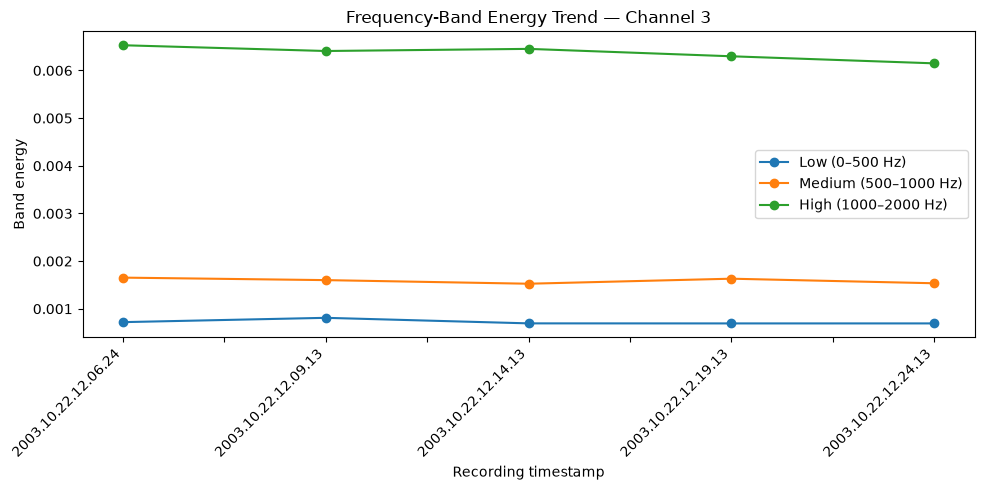

In [5]:
channel3_df = channel_results[
    channel_results["Channel"] == "Channel 3"
].set_index("Recording")

channel3_df[
    ["Low (0–500 Hz)",
     "Medium (500–1000 Hz)",
     "High (1000–2000 Hz)"]
].plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Frequency-Band Energy Trend — Channel 3")
plt.xlabel("Recording timestamp")
plt.ylabel("Band energy")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Channel 3 Frequency-Band Trend Analysis

**Objective:** To observe changes in frequency-band energy across five consecutive selected vibration recordings.

**Observations:**
1. The high-frequency band has the highest energy in all five recordings.
2. High-frequency energy decreases from 0.006529 in the first recording to 0.006149 in the fifth recording.
3. Medium-frequency energy shows small fluctuations across the recordings.
4. Low-frequency energy remains comparatively low and stable.

**Conclusion:** Channel 3 shows a consistent dominance of high-frequency energy, with small variations over the selected timestamps. More recordings and verified bearing-condition labels are required to determine whether these changes are associated with bearing degradation.

**Limitation:** These observations are exploratory and do not independently establish a bearing fault.

,Low (0–500 Hz),Medium (500–1000 Hz),High (1000–2000 Hz)
Recording,,,
2003.10.22.12.06.24,8.09,18.58,73.34
2003.10.22.12.09.13,9.19,18.16,72.66
2003.10.22.12.14.13,8.00,17.59,74.41
2003.10.22.12.19.13,8.04,18.92,73.04
2003.10.22.12.24.13,8.27,18.33,73.40


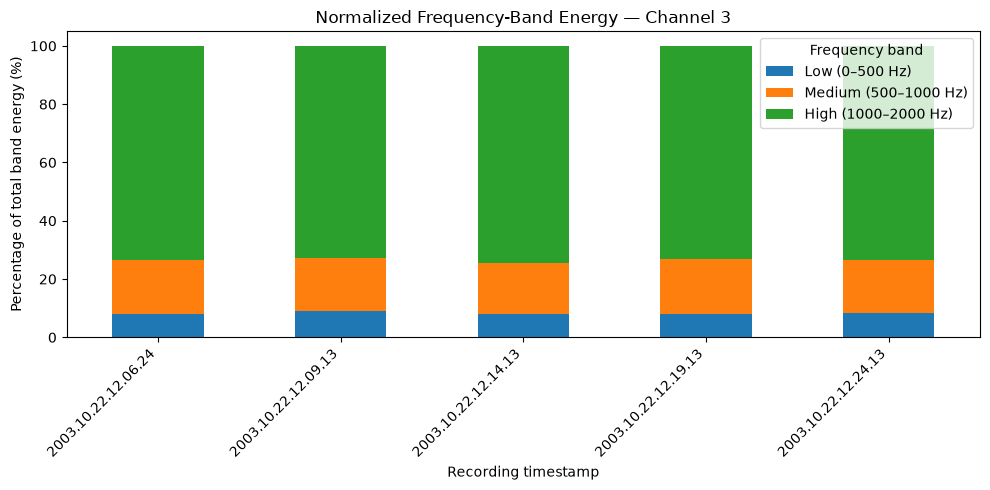

In [6]:
band_columns = [
    "Low (0–500 Hz)",
    "Medium (500–1000 Hz)",
    "High (1000–2000 Hz)"
]

channel3_percent = channel3_df[band_columns].div(
    channel3_df[band_columns].sum(axis=1),
    axis=0
) * 100

display(channel3_percent.round(2))

channel3_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Normalized Frequency-Band Energy — Channel 3")
plt.xlabel("Recording timestamp")
plt.ylabel("Percentage of total band energy (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Frequency band")
plt.tight_layout()
plt.show()

### Normalized Frequency-Band Energy Analysis — Channel 3

**Objective:** To compare the percentage contribution of each frequency band to the total measured band energy.

**Methodology:**
1. Calculated FFT-based energy for the low, medium, and high frequency bands.
2. Divided each band's energy by the sum of energy across the three selected bands.
3. Converted the results into percentages.
4. Visualized the distribution using a stacked bar chart.

**Observations:**
- High-frequency energy contributes approximately 72.66%–74.41% of total band energy.
- Medium-frequency energy contributes approximately 17.59%–18.92%.
- Low-frequency energy contributes approximately 8.00%–9.19%.
- The distribution remains relatively stable across the five recordings.

**Conclusion:** Channel 3 has a dominant high-frequency energy contribution in the selected recordings. The normalized results make it easier to compare frequency distributions even when total energy differs.

**Limitation:** These frequency bands are exploratory. Additional recordings, metadata, and verified bearing-condition labels are required to evaluate their usefulness for fault detection.

In [7]:
band_columns = [
    "Low (0–500 Hz)",
    "Medium (500–1000 Hz)",
    "High (1000–2000 Hz)"
]

all_channel_percent = channel_results.copy()

all_channel_percent[band_columns] = (
    channel_results[band_columns].div(
        channel_results[band_columns].sum(axis=1),
        axis=0
    ) * 100
)

display(all_channel_percent.round(2))

,Recording,Channel,Low (0–500 Hz),Medium (500–1000 Hz),High (1000–2000 Hz)
0,2003.10.22.12.06.24,Channel 1,7.28,12.74,79.99
1,2003.10.22.12.06.24,Channel 2,12.22,15.41,72.37
2,2003.10.22.12.06.24,Channel 3,8.09,18.58,73.34
3,2003.10.22.12.06.24,Channel 4,15.86,20.91,63.23
4,2003.10.22.12.09.13,Channel 1,7.49,12.93,79.58
5,2003.10.22.12.09.13,Channel 2,13.01,16.74,70.25
6,2003.10.22.12.09.13,Channel 3,9.19,18.16,72.66
7,2003.10.22.12.09.13,Channel 4,16.08,18.90,65.02
8,2003.10.22.12.14.13,Channel 1,7.12,12.34,80.54
9,2003.10.22.12.14.13,Channel 2,12.33,15.24,72.43


### Normalized Frequency-Band Analysis Across Four Channels

**Objective:** To compare the relative distribution of vibration energy across four channels using five NASA bearing recordings.

**Methodology:**
1. Loaded five vibration recordings, each containing four channels.
2. Applied FFT to each channel.
3. Calculated energy in three exploratory bands: 0–500 Hz, 500–1000 Hz, and 1000–2000 Hz.
4. Normalized each band's energy by the total energy across these three bands.
5. Compared the percentage contributions across channels and timestamps.

**Results:**
- The high-frequency band was dominant in all four channels.
- Channel 1 showed the highest relative high-frequency contribution, ranging from 79.58% to 80.54%.
- Channel 4 showed a larger relative contribution from the low- and medium-frequency bands than the other channels.
- The normalized distributions varied only slightly across the five selected recordings.

**Conclusion:** The four channels exhibit different frequency-energy distributions, with the high-frequency band dominating each channel. This analysis provides an exploratory baseline for further vibration analysis.

**Limitations:** Only five recordings were examined. The frequency bands are exploratory, and no verified fault labels were used in this comparison. These results cannot independently confirm bearing health, faults, or degradation.

In [8]:

band_columns = [
    "Low (0–500 Hz)",
    "Medium (500–1000 Hz)",
    "High (1000–2000 Hz)"
]

# Average normalized percentages for each channel
channel_summary = (
    all_channel_percent
    .groupby("Channel")[band_columns]
    .mean()
    .round(2)
)

display(channel_summary)


,Low (0–500 Hz),Medium (500–1000 Hz),High (1000–2000 Hz)
Channel,,,
Channel 1,7.27,12.72,80.01
Channel 2,12.16,15.59,72.25
Channel 3,8.32,18.31,73.37
Channel 4,15.61,19.98,64.41


### Final Conclusion: Frequency-Band Analysis

Frequency-band analysis was performed on five NASA bearing vibration recordings containing four channels each. FFT was used to calculate energy in three exploratory frequency bands: 0–500 Hz, 500–1000 Hz, and 1000–2000 Hz.

The average normalized results showed that the high-frequency band dominated all four channels. Channel 1 had the highest average high-frequency contribution (80.01%), while Channel 4 had the highest average low- and medium-frequency contributions (15.61% and 19.98%, respectively).

These findings demonstrate differences in the relative distribution of vibration energy across sensor channels. Further analysis using more recordings, sampling metadata, and verified bearing-condition labels is necessary to determine whether these patterns are useful for fault detection.

**Limitation:** This is an exploratory analysis of five recordings. The selected frequency bands are not validated fault thresholds, and the results do not establish bearing failure or degradation.

In [1]:
data_folder = (
    Path.home() / "Downloads" / "NASA_Bearing_Extracted" / "1st_test" / "1st_test"
)

files = sorted(data_folder.iterdir())[:5]

NameError: name 'Path' is not defined

In [2]:
from pathlib import Path

In [3]:
data_folder = (
    Path.home() / "Downloads" / "NASA_Bearing_Extracted" / "1st_test" / "1st_test"
)

files = sorted(data_folder.iterdir())[:50]

print("Number of recordings selected:", len(files))
print("First recording:", files[0].name)
print("Last recording:", files[-1].name)

Number of recordings selected: 50
First recording: 2003.10.22.12.06.24
Last recording: 2003.10.22.16.44.13


In [4]:

import numpy as np
import pandas as pd
from pathlib import Path

sampling_rate = 20480

bands = {
    "Low (0-500 Hz)": (0, 500),
    "Medium (500-1000 Hz)": (500, 1000),
    "High (1000-2000 Hz)": (1000, 2000)
}

results = []

for file in files:
    df = pd.read_csv(file, sep=r"\s+", header=None)

    for channel in df.columns:
        signal = df[channel].to_numpy(dtype=float, copy=True)
        signal = signal - np.mean(signal)

        fft_values = np.fft.rfft(signal)
        frequencies = np.fft.rfftfreq(
            len(signal), d=1 / sampling_rate
        )
        amplitude = 2 * np.abs(fft_values) / len(signal)

        amplitude[0] /= 2
        if len(signal) % 2 == 0:
            amplitude[-1] /= 2

        row = {
            "Recording": file.name,
            "Channel": f"Channel {channel + 1}"
        }

        for band_name, (low, high) in bands.items():
            mask = (frequencies >= low) & (frequencies < high)
            row[band_name] = np.sum(amplitude[mask] ** 2)

        results.append(row)

frequency_results = pd.DataFrame(results)

print("Total rows:", len(frequency_results))
display(frequency_results.head(10))


Total rows: 400


,Recording,Channel,Low (0-500 Hz),Medium (500-1000 Hz),High (1000-2000 Hz)
0,2003.10.22.12.06.24,Channel 1,0.000420,0.000735,0.004614
1,2003.10.22.12.06.24,Channel 2,0.000438,0.000552,0.002593
2,2003.10.22.12.06.24,Channel 3,0.000720,0.001654,0.006529
3,2003.10.22.12.06.24,Channel 4,0.000992,0.001308,0.003956
4,2003.10.22.12.06.24,Channel 5,0.000607,0.001505,0.002317
5,2003.10.22.12.06.24,Channel 6,0.001237,0.001074,0.001465
6,2003.10.22.12.06.24,Channel 7,0.000434,0.000384,0.001286
7,2003.10.22.12.06.24,Channel 8,0.000418,0.001015,0.001059
8,2003.10.22.12.09.13,Channel 1,0.000417,0.000720,0.004428
9,2003.10.22.12.09.13,Channel 2,0.000457,0.000589,0.002469


In [5]:

# Calculate average energy for each channel and frequency band
average_energy = (
    frequency_results
    .groupby("Channel")[
        ["Low (0-500 Hz)",
         "Medium (500-1000 Hz)",
         "High (1000-2000 Hz)"]
    ]
    .mean()
)

print("Average frequency-band energy by channel:")
display(average_energy.round(6))


Average frequency-band energy by channel:


,Low (0-500 Hz),Medium (500-1000 Hz),High (1000-2000 Hz)
Channel,,,
Channel 1,0.000424,0.000726,0.004667
Channel 2,0.000439,0.000582,0.002808
Channel 3,0.000730,0.001598,0.006329
Channel 4,0.000948,0.001179,0.003801
Channel 5,0.000580,0.001462,0.002367
Channel 6,0.001220,0.001120,0.001470
Channel 7,0.000455,0.000362,0.001288
Channel 8,0.000408,0.001087,0.001112


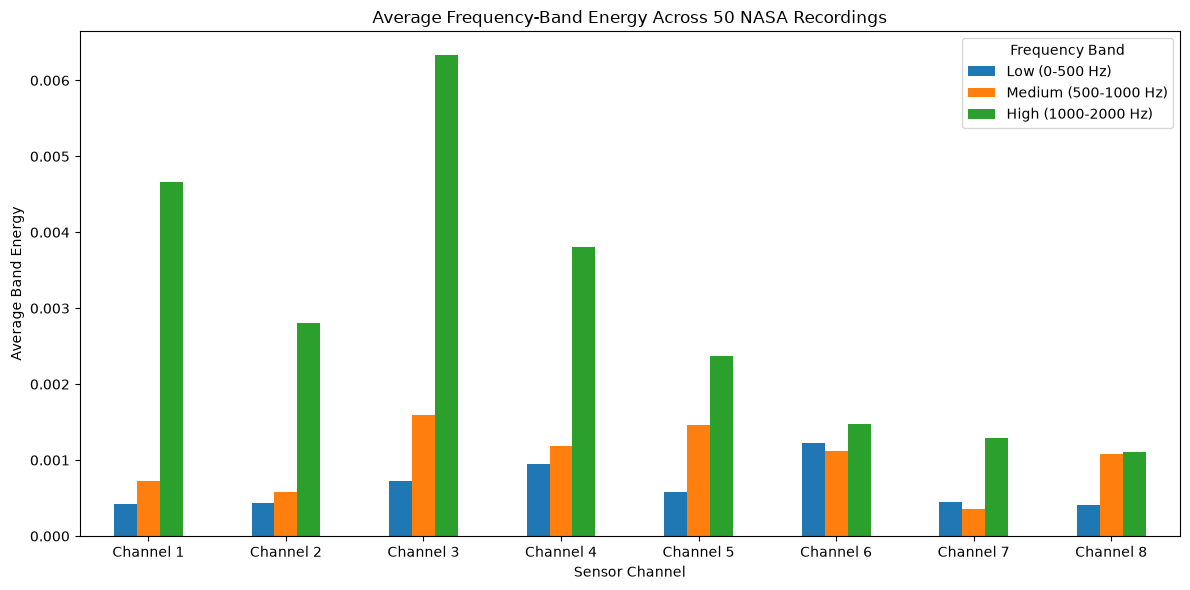

In [6]:

import matplotlib.pyplot as plt

average_energy.plot(kind="bar", figsize=(12, 6))

plt.title("Average Frequency-Band Energy Across 50 NASA Recordings")
plt.xlabel("Sensor Channel")
plt.ylabel("Average Band Energy")
plt.xticks(rotation=0)
plt.legend(title="Frequency Band")
plt.tight_layout()
plt.show()


In [7]:

band_columns = [
    "Low (0-500 Hz)",
    "Medium (500-1000 Hz)",
    "High (1000-2000 Hz)"
]

row_totals = frequency_results[band_columns].sum(axis=1)

normalized_results = frequency_results.copy()
normalized_results[band_columns] = (
    frequency_results[band_columns]
    .div(row_totals.replace(0, np.nan), axis=0)
    * 100
)

average_percentages = (
    normalized_results.groupby("Channel")[band_columns].mean()
)

print("Average normalized frequency-band energy (%):")
display(average_percentages.round(2))


Average normalized frequency-band energy (%):


,Low (0-500 Hz),Medium (500-1000 Hz),High (1000-2000 Hz)
Channel,,,
Channel 1,7.29,12.48,80.23
Channel 2,11.48,15.21,73.32
Channel 3,8.43,18.45,73.12
Channel 4,15.99,19.89,64.12
Channel 5,13.16,33.16,53.68
Channel 6,32.01,29.38,38.61
Channel 7,21.25,17.27,61.48
Channel 8,15.65,41.69,42.66


## Frequency-Band Analysis Across 50 NASA Bearing Recordings

### 1. Objective
To examine vibration signals from 50 NASA bearing recordings and compare their energy distribution across low-, medium-, and high-frequency bands.

### 2. Methodology
- Selected 50 recordings from the NASA bearing dataset.
- Analyzed all 8 sensor channels in each recording, producing 400 channel-recording results.
- Applied the Fast Fourier Transform (FFT) to the mean-centered signals.
- Divided the frequency range into three exploratory bands:
  - Low frequency: 0–500 Hz
  - Medium frequency: 500–1000 Hz
  - High frequency: 1000–2000 Hz
- Calculated band energy using the sum of squared FFT amplitudes.
- Calculated normalized percentages to compare the relative contribution of each band.

### 3. Results and Observations
- Channel 1 had the highest average relative high-frequency contribution at 80.23%.
- Channel 3 had the highest average absolute high-frequency band energy, approximately 0.006329.
- Channels 1, 2, 3, 4, and 7 had their largest normalized contribution in the high-frequency band.
- Channel 5 had a medium-frequency contribution of 33.16%.
- Channel 6 had a low-frequency contribution of 32.01%.
- Channel 8 had similar medium- and high-frequency contributions of 41.69% and 42.66%, respectively.

### 4. Conclusion
The analysis shows that the distribution of vibration energy differs among the eight channels. The high-frequency band dominates the normalized energy distribution in five channels, while Channels 5, 6, and 8 show different distributions. Channel 3 has the greatest average absolute high-band energy, whereas Channel 1 has the greatest relative high-band contribution.

### 5. Limitations
This is an exploratory analysis of 50 recordings. The selected frequency bands are not validated fault thresholds. These results alone cannot confirm bearing faults. Further work should examine more recordings, verify the sampling-rate metadata and bearing condition labels, and compare the results with known healthy and faulty conditions.